# Notebook 4 — Interpretabilidade com SHAP

**TCC — Desenvolvimento de modelo preditivo interpretável de machine learning para
identificação de alunos em risco de evasão no ensino superior**
Curso de Sistemas de Informação — UEMG

---

## Objetivo

Fase 5 do CRISP-DM (*Evaluation*). Os notebooks anteriores responderam **quem** está em risco de
evadir. Este responde **por quê** — e é aqui que o trabalho cumpre o "interpretável" do título.

## Por que a interpretabilidade não é um acessório

Um modelo que apenas devolve uma lista de nomes em risco **não diz o que fazer**. Considere dois
alunos com probabilidade de evasão de 0,85:

- o primeiro está sinalizado por **inadimplência e ausência de bolsa** → demanda a assistência
  estudantil;
- o segundo, por **reprovações sucessivas com mensalidades em dia** → demanda apoio pedagógico.

São intervenções diferentes, executadas por setores diferentes, com custos diferentes. Sem explicação
individual, a coordenação recebe os dois na mesma lista e trata os dois do mesmo jeito — o que
desperdiça recurso e, no limite, faz o sistema perder credibilidade interna.

Além disso, o Notebook 3 produziu um argumento independente a favor desta fase: Random Forest e
XGBoost têm **métricas agregadas idênticas** e ainda assim **discordam sobre 24 alunos**. Métricas
agregadas resumem o placar, não a decisão individual. Quando o produto é uma lista de nomes,
a explicação por aluno **faz parte da avaliação do modelo**, não é um adorno dela.

## Estrutura

| Seção | Pergunta respondida |
|---|---|
| 3–4 | Quais variáveis o modelo mais usa? (importância global) |
| 5–6 | Em que **direção** cada variável empurra o risco? |
| 7 | Qual a contribuição real das variáveis categóricas, somando suas *dummies*? |
| 8 | Os achados coincidem com os dos Notebooks 1 e 2? |
| 9 | Como o efeito de uma variável muda ao longo de sua faixa de valores? |
| 10 | Por que **este** aluno específico foi sinalizado? |
| 11–12 | O que a literatura diz, e o que a gestão deve fazer? |

## 1. Configuração e carga do modelo

In [1]:
# --- Bibliotecas -------------------------------------------------------------
import os
import sys
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

DIR_DADOS = "dados"
DIR_FIGURAS = "figuras"
DIR_MODELOS = "modelos"

if "src" not in sys.path:
    sys.path.insert(0, "src")
from data_loader import rotulo   # noqa: E402

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.labelsize": 11,
})

def salvar(nome):
    caminho = os.path.join(DIR_FIGURAS, nome)
    plt.savefig(caminho)
    print(f"[figura salva] {caminho}")

print(f"shap {shap.__version__} | Ambiente pronto | SEED = {SEED}")

shap 0.52.0 | Ambiente pronto | SEED = 42


C:\Codigos_Git\Pessoal\tcc-dropout-prediction\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# --- Modelo escolhido no Notebook 3 -----------------------------------------
pipeline = joblib.load(os.path.join(DIR_MODELOS, "melhor_modelo.joblib"))
modelo = pipeline.named_steps["modelo"]      # o SMOTE é inerte na predição

with open(os.path.join(DIR_MODELOS, "info_melhor_modelo.json"), encoding="utf-8") as fh:
    INFO = json.load(fh)
with open(os.path.join(DIR_DADOS, "metadados.json"), encoding="utf-8") as fh:
    META = json.load(fh)

CLASSES = {int(k): v for k, v in META["classes"].items()}

# --- Conjunto de teste (o mesmo, intocado, do Notebook 2) -------------------
X_teste = pd.read_csv(os.path.join(DIR_DADOS, "X_test.csv"))
y_teste = pd.read_csv(os.path.join(DIR_DADOS, "y_test.csv"))["target"]

y_pred = pipeline.predict(X_teste)
y_prob = pipeline.predict_proba(X_teste)[:, 1]

print(f"Modelo      : {INFO['melhor_modelo']} ({INFO['tipo_estimador']})")
print(f"Classe 1    : {META['classe_positiva']}")
print(f"Teste       : {X_teste.shape[0]} alunos x {X_teste.shape[1]} features")
print(f"F1 conferido: {INFO['metricas_teste']['F1']:.4f}")
print()
print("Hiperparâmetros relevantes:")
for chave in ("n_estimators", "max_depth", "learning_rate", "subsample", "colsample_bytree"):
    print(f"   {chave:<18} = {INFO['hiperparametros'][chave]}")

Modelo      : XGBoost (XGBClassifier)
Classe 1    : Dropout
Teste       : 726 alunos x 105 features
F1 conferido: 0.9059

Hiperparâmetros relevantes:
   n_estimators       = 200
   max_depth          = 3
   learning_rate      = 0.1
   subsample          = 1.0
   colsample_bytree   = 0.8


In [3]:
# --- Rótulos em português para os gráficos ----------------------------------
# `rotulo()` também traduz as dummies: application_mode_1 -> "Modalidade de ingresso = 1"
NOMES_PT = [rotulo(c) for c in X_teste.columns]

duplicados = pd.Series(NOMES_PT).duplicated().sum()
assert duplicados == 0, f"{duplicados} rótulos duplicados — os gráficos ficariam ambíguos"

X_pt = X_teste.copy()
X_pt.columns = NOMES_PT

print(f"{len(NOMES_PT)} rótulos gerados, todos únicos. Exemplos:")
for original, traduzido in list(zip(X_teste.columns, NOMES_PT))[:3]:
    print(f"   {original:<38} -> {traduzido}")
for original, traduzido in list(zip(X_teste.columns, NOMES_PT))[-3:]:
    print(f"   {original:<38} -> {traduzido}")

105 rótulos gerados, todos únicos. Exemplos:
   previous_qualification_grade           -> Nota da formação anterior
   admission_grade                        -> Nota de admissão
   age_at_enrollment                      -> Idade no ingresso
   fathers_occupation_10                  -> Ocupação do pai = 10
   fathers_occupation_90                  -> Ocupação do pai = 90
   fathers_occupation_infrequent_sklearn  -> Ocupação do pai = outras (raras)


## 2. O que os valores SHAP são — e o que não são

**SHAP** (*SHapley Additive exPlanations*, Lundberg & Lee, 2017) importa da teoria dos jogos
cooperativos o conceito de **valor de Shapley**: a forma matematicamente única de repartir o
resultado de um jogo entre os jogadores que o produziram, respeitando quatro axiomas (eficiência,
simetria, linearidade e tratamento de jogadores nulos).

Traduzindo para o problema: as **variáveis** são os jogadores e a **predição** é o resultado a
repartir. O valor SHAP de uma variável, para um aluno específico, é sua contribuição média marginal
considerando **todas as ordens possíveis** de entrada das variáveis no modelo.

### A propriedade que faz o SHAP diferente

$$\text{predição}(aluno) = \text{valor base} + \sum_{i=1}^{105} \text{SHAP}_i(aluno)$$

A explicação é **exatamente aditiva**: a soma das contribuições reconstrói a predição, sem resíduo.
Isso não é aproximação — é garantia matemática, e a seção 3 a verifica numericamente.

| Propriedade | Consequência prática |
|---|---|
| **Aditividade exata** | A explicação não "sobra" nem "falta" — pode ser auditada |
| **Local** | Cada aluno tem seus próprios valores; a explicação é individual, não uma média |
| **Com sinal** | Positivo empurra para evasão, negativo para conclusão. A **direção** é explícita |
| **Consistente** | Se uma variável passa a contribuir mais em qualquer cenário, seu valor SHAP não diminui |

### Por que isso corrige as duas limitações do Notebook 2

O diagnóstico de importância da Fase 3 usou redução de impureza do Random Forest, e o próprio
notebook registrou suas duas falhas. O SHAP resolve ambas:

| Limitação da importância por impureza | Como o SHAP resolve |
|---|---|
| **Não informa direção** — diz que "idade importa", não se idade alta aumenta ou reduz o risco | Valores têm sinal, por aluno |
| **Enviesada** para variáveis com muitos valores distintos | Os axiomas de Shapley garantem atribuição justa independente de cardinalidade |

### Uma advertência necessária: SHAP não é causalidade

> O valor SHAP mede **como o modelo usa a variável**, não como o mundo funciona. Se o SHAP mostra que
> inadimplência empurra o risco para cima, a leitura correta é *"o modelo aprendeu a associar
> inadimplência a evasão nestes dados"* — e não *"quitar a dívida do aluno reduz seu risco em X"*.
>
> A segunda afirmação é causal e exigiria delineamento experimental (um ensaio com atribuição
> aleatória de auxílio financeiro). A distinção precisa ser mantida ao escrever as recomendações da
> seção 12: SHAP indica **onde olhar**, não garante **o que funciona**.

### Escala: log-odds, não probabilidade

O XGBoost soma valores em **log-odds** (o logaritmo da razão de chances). Os valores SHAP herdam
essa escala, o que preserva a aditividade exata mas exige atenção na leitura: um SHAP de +1,0 não
significa "+100% de risco". A conversão é:

$$P = \frac{1}{1 + e^{-\text{log-odds}}}$$

A seção 10 apresenta os casos individuais nas **duas** escalas, para que a interpretação seja direta.

## 3. Cálculo dos valores SHAP

`shap.TreeExplainer` é o algoritmo **TreeSHAP**: para modelos baseados em árvores, calcula os valores
de Shapley **exatos** em tempo polinomial, aproveitando a estrutura das árvores. Não há amostragem
nem aproximação — diferente do `KernelExplainer`, que seria necessário para modelos opacos.

In [4]:
# --- Explainer e valores SHAP para todo o conjunto de teste -----------------
explainer = shap.TreeExplainer(modelo)
shap_valores = explainer(X_pt)          # objeto Explanation (valores + dados + nomes)

VALOR_BASE = float(np.unique(shap_valores.base_values)[0])

print(f"Valores SHAP: {shap_valores.values.shape[0]} alunos x {shap_valores.values.shape[1]} features")
print()
print(f"Valor base (log-odds) : {VALOR_BASE:+.4f}")
print(f"Valor base (probab.)  : {1 / (1 + np.exp(-VALOR_BASE)):.4f}")
print()
print("O valor base é a predição do modelo na ausência de informação sobre o aluno.")
print("Note que ele fica próximo de 0,50 — reflexo do treino balanceado pelo SMOTE,")
print("e NÃO da taxa real de evasão de 39,1% observada no conjunto de teste.")

Valores SHAP: 726 alunos x 105 features

Valor base (log-odds) : +0.0101
Valor base (probab.)  : 0.5025

O valor base é a predição do modelo na ausência de informação sobre o aluno.
Note que ele fica próximo de 0,50 — reflexo do treino balanceado pelo SMOTE,
e NÃO da taxa real de evasão de 39,1% observada no conjunto de teste.


In [5]:
# --- Verificação da aditividade ---------------------------------------------
# Propriedade central do SHAP: valor base + soma das contribuições = predição.
margem_modelo = modelo.predict(X_teste, output_margin=True)   # log-odds do XGBoost
margem_shap = shap_valores.values.sum(axis=1) + shap_valores.base_values

erro_max = float(np.abs(margem_shap - margem_modelo).max())
situacao = "[OK]" if erro_max < 1e-4 else "[FALHA]"

print("VERIFICAÇÃO DA ADITIVIDADE")
print(f"   erro máximo em 726 alunos: {erro_max:.2e}")
print(f"   {situacao} A explicação reconstrói a predição do modelo.")
print()
print("O resíduo é da ordem da precisão de ponto flutuante de 32 bits — ou seja,")
print("a explicação é exata, não aproximada. Isso é auditável: qualquer valor SHAP")
print("apresentado neste notebook pode ser somado de volta à predição original.")

assert erro_max < 1e-4, "Aditividade violada — não prosseguir com a interpretação."

VERIFICAÇÃO DA ADITIVIDADE
   erro máximo em 726 alunos: 3.81e-06
   [OK] A explicação reconstrói a predição do modelo.

O resíduo é da ordem da precisão de ponto flutuante de 32 bits — ou seja,
a explicação é exata, não aproximada. Isso é auditável: qualquer valor SHAP
apresentado neste notebook pode ser somado de volta à predição original.


## 4. Importância global — quais variáveis o modelo mais usa

O gráfico abaixo ordena as variáveis pela **média do valor absoluto** de SHAP em todos os 726 alunos
do teste. Usar o valor absoluto responde "o quanto esta variável move a predição, em qualquer
direção" — a magnitude do efeito, sem cancelamento entre alunos empurrados para lados opostos.

[figura salva] figuras\12_shap_importancia_global.png


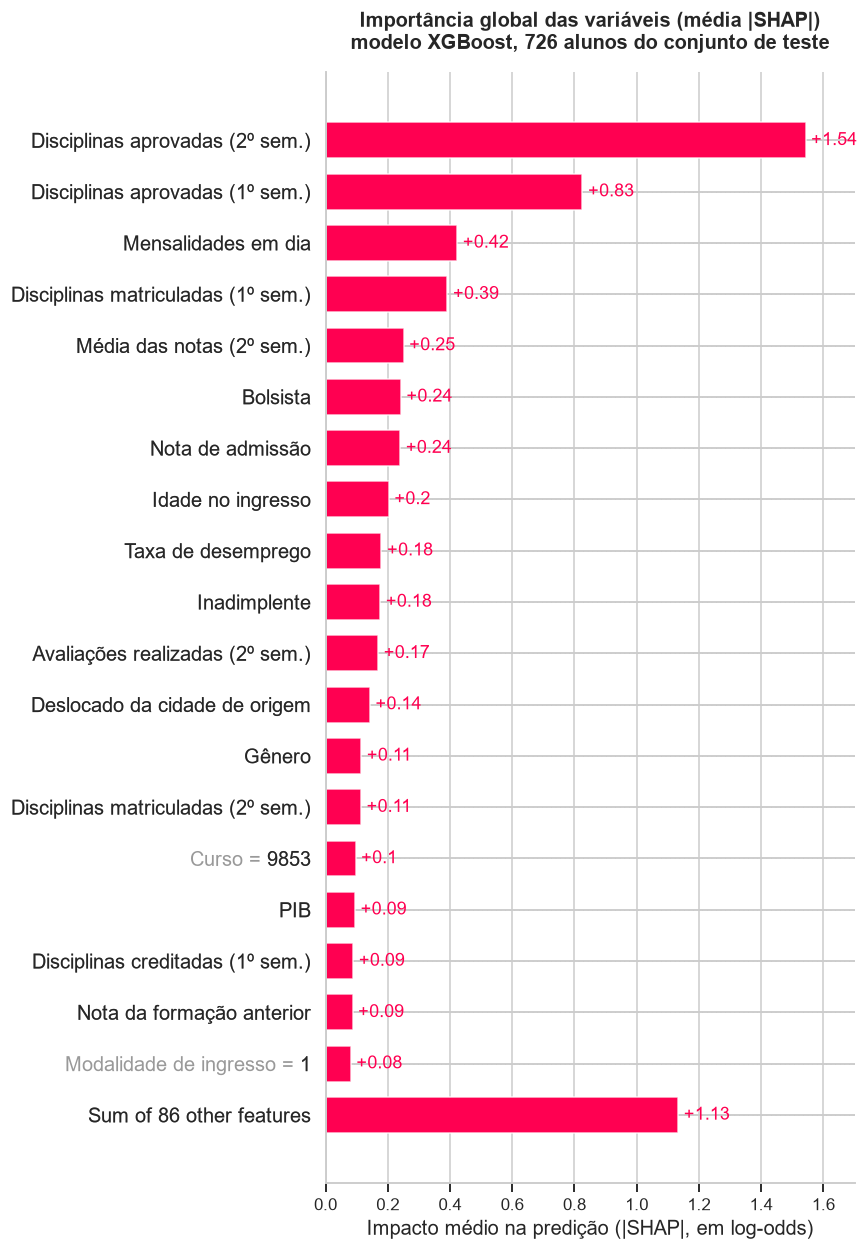

In [6]:
plt.figure(figsize=(10, 8))
shap.plots.bar(shap_valores, max_display=20, show=False)
plt.title("Importância global das variáveis (média |SHAP|)\n"
          "modelo XGBoost, 726 alunos do conjunto de teste", fontweight="bold", pad=15)
plt.xlabel("Impacto médio na predição (|SHAP|, em log-odds)")
plt.tight_layout()
salvar("12_shap_importancia_global.png")
plt.show()

In [7]:
# --- Tabela da importância global -------------------------------------------
importancia = (
    pd.DataFrame({
        "variavel": NOMES_PT,
        "shap_medio_abs": np.abs(shap_valores.values).mean(axis=0),
    })
    .sort_values("shap_medio_abs", ascending=False)
    .reset_index(drop=True)
)
importancia.index += 1
importancia["% do total"] = (
    importancia["shap_medio_abs"] / importancia["shap_medio_abs"].sum() * 100).round(2)
importancia["% acumulado"] = importancia["% do total"].cumsum().round(2)

print("TOP 15 — importância global por SHAP")
display(importancia.head(15).round(4))

for k in (3, 5, 10, 20):
    print(f"   top {k:>2} variáveis concentram "
          f"{importancia['% acumulado'].iloc[k - 1]:5.1f}% do impacto total")

nulas = int((importancia["shap_medio_abs"] < 1e-6).sum())
print(f"\nVariáveis com impacto praticamente nulo (|SHAP| < 1e-6): {nulas} de {len(importancia)}")

TOP 15 — importância global por SHAP


,variavel,shap_medio_abs,% do total,% acumulado
1,Disciplinas aprovadas (2º sem.),1.5425,23.379999,23.379999
2,Disciplinas aprovadas (1º sem.),0.8258,12.520000,35.900002
3,Mensalidades em dia,0.4232,6.420000,42.320000
4,Disciplinas matriculadas (1º sem.),0.3918,5.940000,48.259998
5,Média das notas (2º sem.),0.2509,3.800000,52.060001
6,Bolsista,0.2419,3.670000,55.730000
7,Nota de admissão,0.2401,3.640000,59.369999
8,Idade no ingresso,0.2032,3.080000,62.450001
9,Taxa de desemprego,0.1799,2.730000,65.180000
10,Inadimplente,0.1758,2.670000,67.849998


   top  3 variáveis concentram  42.3% do impacto total
   top  5 variáveis concentram  52.1% do impacto total
   top 10 variáveis concentram  67.8% do impacto total
   top 20 variáveis concentram  83.9% do impacto total

Variáveis com impacto praticamente nulo (|SHAP| < 1e-6): 24 de 105


> ### Leitura — importância global
>
> A hierarquia confirma, por um terceiro método independente, o que os Notebooks 1 e 2 já indicavam:
> **desempenho acadêmico do 2º semestre** no topo, seguido pelo 1º semestre e pelo bloco
> **financeiro**. A seção 8 compara os três métodos formalmente.
>
> Dois pontos que só o SHAP revela:
>
> 1. **A concentração no topo é extrema.** Uma única variável — disciplinas aprovadas no 2º semestre —
>    responde por **23,4%** de todo o impacto, contra 17,8% que a importância por impureza lhe atribuía.
>    As três primeiras somam **42,3%** e as dez primeiras, **67,8%**. Na prática, o modelo é muito mais
>    simples do que suas 105 features fazem parecer — e isso é boa notícia para a comunicação com a
>    gestão: o sistema pode ser explicado em termos de meia dúzia de indicadores.
> 2. **24 das 105 features têm impacto praticamente nulo** (|SHAP| < 10⁻⁶). Foram mantidas de propósito
>    (decisão D-17), e o SHAP agora quantifica o custo dessa decisão: **zero**. Manter as variáveis não
>    degradou o modelo — apenas não ajudou. É a validação empírica de que não fazer seleção agressiva
>    foi inócuo, não prejudicial.
> 3. **A média das notas caiu para a 5ª posição.** Nos Notebooks 1 e 2 ela aparecia entre as duas
>    primeiras. O SHAP mostra que, condicionado ao **número de aprovações**, saber a média agrega pouco
>    — as duas variáveis carregam informação redundante, e o modelo prefere a contagem. É o primeiro
>    sinal de que efeito marginal e efeito condicional divergem neste conjunto (ver seção 6.1).
>
> **Cuidado ao interpretar:** este gráfico mostra **magnitude, não direção**. Uma variável no topo
> pode estar empurrando alunos para evasão, para conclusão, ou para lados opostos em subgrupos
> diferentes. É o que a próxima seção resolve.

## 5. Impacto e direção — o gráfico *beeswarm*

Este é o gráfico mais informativo do notebook, e vale explicar como lê-lo antes de exibi-lo:

- **cada ponto é um aluno** — são 726 pontos por linha;
- a **posição horizontal** é o valor SHAP: à direita empurra para **evasão**, à esquerda para
  **conclusão**;
- a **cor** é o valor da variável para aquele aluno: **vermelho = alto**, **azul = baixo**;
- a **espessura vertical** mostra acumulação de alunos naquele valor de SHAP.

A combinação de posição e cor revela a direção do efeito. Se os pontos vermelhos se concentram à
direita, valores **altos** da variável **aumentam** o risco. Se à esquerda, valores altos **protegem**.

[figura salva] figuras\13_shap_beeswarm.png


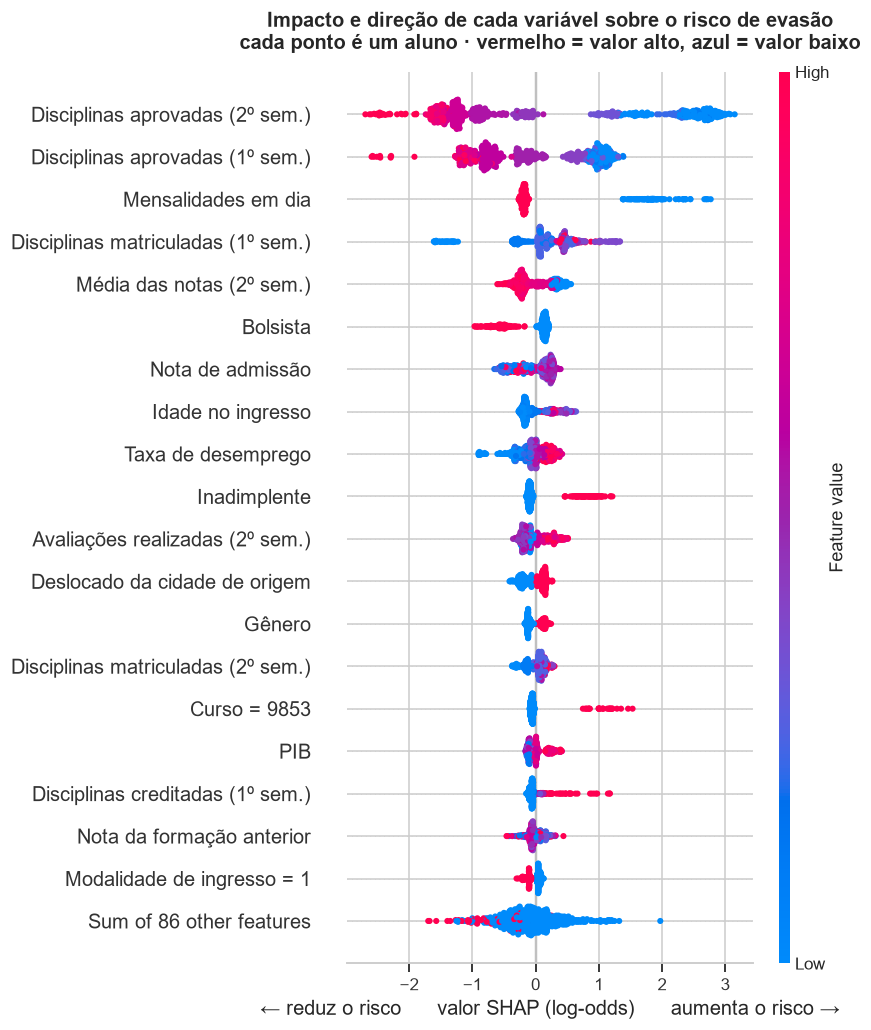

In [8]:
plt.figure(figsize=(11, 9))
shap.plots.beeswarm(shap_valores, max_display=20, show=False)
plt.title("Impacto e direção de cada variável sobre o risco de evasão\n"
          "cada ponto é um aluno · vermelho = valor alto, azul = valor baixo",
          fontweight="bold", pad=15)
plt.xlabel("← reduz o risco      valor SHAP (log-odds)      aumenta o risco →")
plt.tight_layout()
salvar("13_shap_beeswarm.png")
plt.show()

## 6. Direção quantificada

O *beeswarm* mostra a direção visualmente, mas uma banca pode pedir o número. A tabela abaixo calcula,
para cada variável, a **correlação de Spearman entre o valor da variável e seu valor SHAP**.

A leitura é direta:

- **correlação positiva** → valores altos da variável **aumentam** o risco de evasão;
- **correlação negativa** → valores altos **protegem** contra a evasão;
- **correlação próxima de zero com |SHAP| alto** → o efeito **não é monotônico**: a variável importa,
  mas seu efeito muda de sinal ao longo da faixa de valores (caso investigado na seção 9).

Usa-se Spearman, e não Pearson, porque o interesse é na consistência da **ordem** do efeito, não em
sua linearidade.

In [9]:
from scipy.stats import spearmanr

linhas = []
for i, nome in enumerate(NOMES_PT):
    valores = X_teste.iloc[:, i].to_numpy()
    shaps = shap_valores.values[:, i]
    if np.std(valores) < 1e-12 or np.std(shaps) < 1e-12:
        rho = np.nan
    else:
        rho = spearmanr(valores, shaps).statistic
    linhas.append({"variavel": nome,
                   "impacto_medio": np.abs(shaps).mean(),
                   "rho_valor_x_shap": rho})

def classificar(rho):
    if pd.isna(rho):
        return "sem variação"
    if rho > 0.30:
        return "AUMENTA o risco"
    if rho < -0.30:
        return "REDUZ o risco"
    return "não monotônico"

direcao = (pd.DataFrame(linhas)
             .sort_values("impacto_medio", ascending=False)
             .head(15).reset_index(drop=True))
direcao.index += 1
direcao["efeito de valor alto"] = direcao["rho_valor_x_shap"].map(classificar)

print("DIREÇÃO DO EFEITO — top 15 variáveis por impacto")
display(direcao.round(4))

DIREÇÃO DO EFEITO — top 15 variáveis por impacto


,variavel,impacto_medio,rho_valor_x_shap,efeito de valor alto
1,Disciplinas aprovadas (2º sem.),1.5425,-0.9667,REDUZ o risco
2,Disciplinas aprovadas (1º sem.),0.8258,-0.9564,REDUZ o risco
3,Mensalidades em dia,0.4232,-0.6043,REDUZ o risco
4,Disciplinas matriculadas (1º sem.),0.3918,0.7180,AUMENTA o risco
5,Média das notas (2º sem.),0.2509,-0.8944,REDUZ o risco
6,Bolsista,0.2419,-0.7394,REDUZ o risco
7,Nota de admissão,0.2401,0.2541,não monotônico
8,Idade no ingresso,0.2032,0.7864,AUMENTA o risco
9,Taxa de desemprego,0.1799,0.9429,AUMENTA o risco
10,Inadimplente,0.1758,0.5540,AUMENTA o risco


[figura salva] figuras\14_shap_impacto_direcao.png


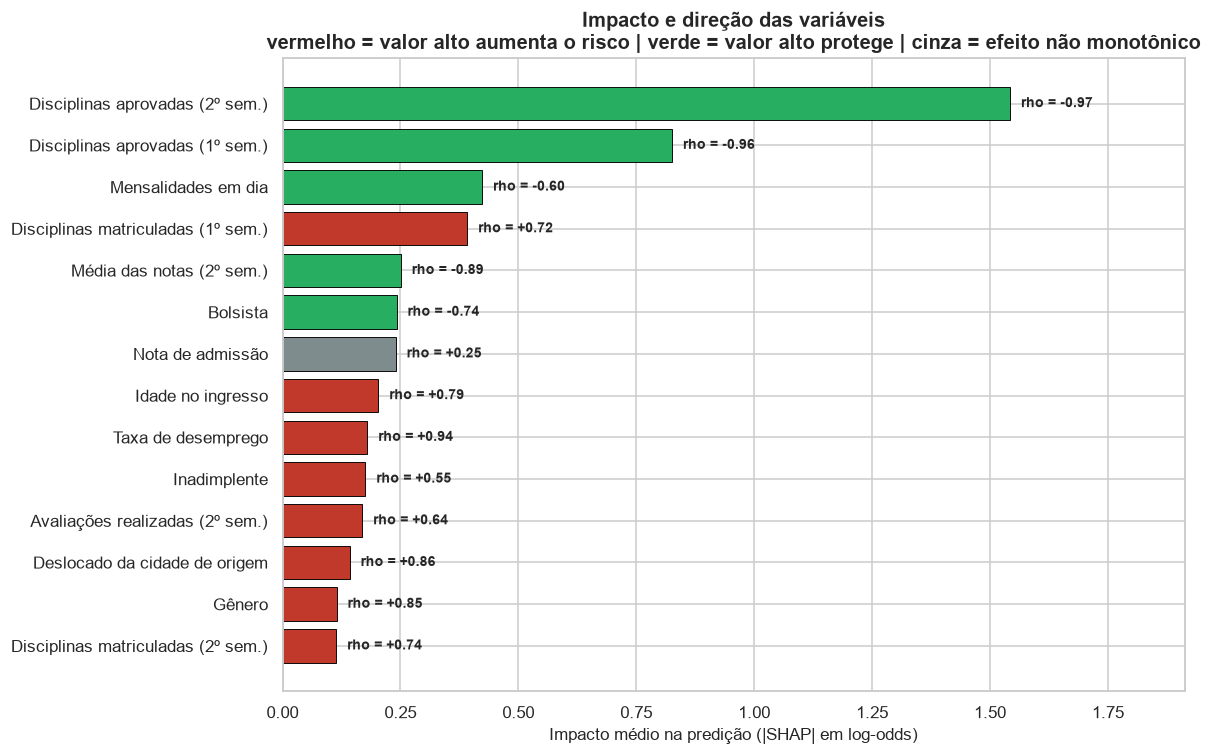

In [10]:
# --- Gráfico: impacto x direção --------------------------------------------
top = direcao.head(14).iloc[::-1]
cores = ["#c0392b" if r > 0.30 else "#27ae60" if r < -0.30 else "#7f8c8d"
         for r in top["rho_valor_x_shap"]]

fig, ax = plt.subplots(figsize=(11, 7))
barras = ax.barh(top["variavel"], top["impacto_medio"], color=cores,
                 edgecolor="black", linewidth=0.6)

for barra, rho in zip(barras, top["rho_valor_x_shap"]):
    texto = "n/d" if pd.isna(rho) else f"rho = {rho:+.2f}"
    ax.text(barra.get_width() + top["impacto_medio"].max() * 0.015,
            barra.get_y() + barra.get_height() / 2, texto,
            va="center", fontsize=9, fontweight="bold")

ax.set_xlabel("Impacto médio na predição (|SHAP| em log-odds)")
ax.set_xlim(0, top["impacto_medio"].max() * 1.24)
ax.set_title("Impacto e direção das variáveis\n"
             "vermelho = valor alto aumenta o risco | verde = valor alto protege | "
             "cinza = efeito não monotônico", fontweight="bold")
plt.tight_layout()
salvar("14_shap_impacto_direcao.png")
plt.show()

> ### Leitura — direção do efeito
>
> Esta tabela é o **resultado central do trabalho** e a base das recomendações da seção 12. Ela
> converte o modelo em um conjunto de afirmações verificáveis sobre o risco de evasão, cada uma com
> magnitude e direção.
>
> As direções confirmam o esperado na maior parte dos casos: mais aprovações e mensalidades em dia
> **protegem**; idade maior e inadimplência **aumentam** o risco.
>
> Mas três resultados **contrariam** o que os Notebooks 1 e 2 indicavam, e não são erro — são o achado
> mais interessante desta fase. A subseção seguinte os investiga.
>
> Note também **Nota de admissão** classificada como *não monotônica* (rho = +0,25 com impacto
> relevante): o modelo aprendeu uma relação que muda de sinal ao longo da faixa — algo que nem a
> correlação linear nem a importância por impureza conseguiriam detectar.

### 6.1 Quando o efeito condicional contraria o efeito marginal

Três variáveis receberam do SHAP uma direção **oposta** à que a análise descritiva do Notebook 1
indicava. Isso não é inconsistência: é a diferença entre duas perguntas distintas.

| Pergunta | Como se mede | O que responde |
|---|---|---|
| **Efeito marginal** | Correlação simples, taxa de evasão por grupo | "Alunos com esta característica evadem mais?" |
| **Efeito condicional** | Valor SHAP | "**Dado tudo o mais que já sei do aluno**, esta característica agrega risco?" |

Quando as duas divergem, é porque a associação marginal era **explicada por outra variável**. A célula
abaixo quantifica os três casos.

In [11]:
# --- Efeito marginal x efeito condicional -----------------------------------
# Recarrega o dataset original: o efeito marginal precisa ser medido nos valores
# brutos, nao nos padronizados que alimentaram o modelo.
df_limpo = pd.read_csv(os.path.join(DIR_DADOS, "dataset_limpo.csv"))

b = df_limpo[df_limpo["target"] != "Enrolled"].copy()
b["evadiu"] = (b["target"] == "Dropout").astype(int)
taxa_base = b["evadiu"].mean()

INVESTIGAR = ["displaced", "curricular_units_1st_sem_enrolled", "unemployment_rate"]

print(f"Taxa de evasão de referência: {taxa_base:.1%}")
print()
for col in INVESTIGAR:
    i = list(X_teste.columns).index(col)
    rho_shap = spearmanr(X_teste.iloc[:, i], shap_valores.values[:, i]).statistic
    corr_marginal = b[col].corr(b["evadiu"])

    print("=" * 74)
    print(f"{rotulo(col)}")
    print("=" * 74)
    print(f"   efeito MARGINAL    (correlação com evasão) : {corr_marginal:+.4f}")
    print(f"   efeito CONDICIONAL (rho valor x SHAP)      : {rho_shap:+.4f}")
    print(f"   impacto SHAP médio                         : "
          f"{np.abs(shap_valores.values[:, i]).mean():.4f}"
          f"  (posição {list(importancia['variavel']).index(rotulo(col)) + 1} de 105)")

    if b[col].nunique() <= 3:
        for valor, grupo in b.groupby(col):
            print(f"      valor {valor}: evasão {grupo['evadiu'].mean():5.1%}  (n = {len(grupo):>4})")
    else:
        quintis = pd.qcut(b[col], q=4, duplicates="drop")
        for faixa, grupo in b.groupby(quintis, observed=True):
            print(f"      {str(faixa):<16} evasão {grupo['evadiu'].mean():5.1%}  (n = {len(grupo):>4})")

    # Com correlacao marginal proxima de zero, nao ha sinal a inverter: o efeito
    # simplesmente nao existe no marginal e aparece no condicional.
    if abs(corr_marginal) < 0.05:
        sinal = "efeito que EMERGE no condicional (marginal indistinguivel de zero)"
    elif corr_marginal * rho_shap < 0:
        sinal = "INVERSAO de sinal entre marginal e condicional"
    else:
        sinal = "mesma direcao nos dois"
    print(f"   -> {sinal}")
    print()

Taxa de evasão de referência: 39.1%



Deslocado da cidade de origem
   efeito MARGINAL    (correlação com evasão) : -0.1261
   efeito CONDICIONAL (rho valor x SHAP)      : +0.8608
   impacto SHAP médio                         : 0.1424  (posição 12 de 105)
      valor 0: evasão 45.9%  (n = 1637)
      valor 1: evasão 33.6%  (n = 1993)
   -> INVERSAO de sinal entre marginal e condicional

Disciplinas matriculadas (1º sem.)
   efeito MARGINAL    (correlação com evasão) : -0.1611
   efeito CONDICIONAL (rho valor x SHAP)      : +0.7180
   impacto SHAP médio                         : 0.3918  (posição 4 de 105)
      (-0.001, 5.0]    evasão 57.1%  (n =  944)
      (5.0, 6.0]       evasão 38.0%  (n = 1594)
      (6.0, 7.0]       evasão 30.0%  (n =  546)
      (7.0, 26.0]      evasão 20.7%  (n =  546)
   -> INVERSAO de sinal entre marginal e condicional

Taxa de desemprego
   efeito MARGINAL    (correlação com evasão) : -0.0042
   efeito CONDICIONAL (rho valor x SHAP)      : +0.9429
   impacto SHAP médio                         : 0

> ### Leitura — as três divergências
>
> **1. Deslocado da cidade de origem — inversão de sinal.** Marginalmente, morar fora da cidade de
> origem *protege*: 33,6% de evasão contra 45,9% de quem mora na própria cidade. Condicionalmente, o
> SHAP inverte o sinal (rho = +0,86). A explicação plausível é **confundimento**: o aluno deslocado
> tende a ser o que passou em curso concorrido, com nota de admissão maior e dedicação exclusiva. Uma
> vez que o modelo já conhece nota de admissão, idade e desempenho, o que resta do "estar deslocado" é
> o **custo real de morar longe** — e esse resíduo aumenta o risco.
>
> **2. Disciplinas matriculadas no 1º semestre — inversão de sinal.** Marginalmente, matricular-se em
> mais disciplinas está associado a *menos* evasão (r = −0,16). Condicionalmente, o SHAP aponta o
> contrário (rho = +0,72), e a variável é a **4ª mais importante** do modelo. A leitura é direta e
> importante: dado o número de disciplinas **aprovadas**, matricular-se em muitas passa a ser sinal de
> **sobrecarga e reprovação acumulada**. Matricular-se em 8 e aprovar 6 é uma coisa; matricular-se em 8
> e aprovar 1 é outra completamente diferente — e é exatamente essa razão implícita que o modelo
> aprendeu a usar.
>
> **3. Taxa de desemprego — efeito que emerge do nada.** Este é o caso mais notável. A correlação
> marginal com a evasão é de **−0,004** — estatisticamente indistinguível de zero. E a tabela de
> quartis mostra por quê: a relação marginal tem **forma de U** (41,0% → 38,2% → 35,3% → 43,2%), de
> modo que uma correlação linear a mede como nula por cancelamento, não por ausência de relação. Ainda assim, o
> desemprego é a **9ª variável mais importante** do modelo, com direção altamente consistente
> (rho = +0,94: desemprego alto aumenta o risco). Uma variável que a análise descritiva descartaria como
> irrelevante revela-se substancial quando condicionada às demais.
>
> ### Por que isso importa para o TCC
>
> Estes três casos são o argumento mais forte que o trabalho tem a favor da interpretabilidade baseada
> em SHAP:
>
> - **A análise descritiva do Notebook 1 teria levado a conclusões erradas** sobre estas três variáveis
>   — inclusive à tentação de descartar a taxa de desemprego por correlação nula. A decisão D-17 (não
>   fazer seleção de variáveis) está agora justificada por evidência, não apenas por princípio.
> - **A importância por impureza do Notebook 2 acertaria a magnitude, mas não a direção**, e a direção
>   é justamente o que a gestão precisa para decidir o que fazer.
> - **Serve de advertência metodológica geral:** em um modelo com 105 variáveis correlacionadas, o
>   efeito marginal de uma variável isolada e sua contribuição dentro do modelo são grandezas
>   diferentes. Confundi-las é o erro mais comum na leitura de resultados de machine learning aplicado.
>
> **Ressalva obrigatória:** nada disso é causalidade. Que o desemprego contribua condicionalmente para
> a predição não significa que uma queda no desemprego reduziria a evasão em alguma magnitude
> estimável. Vale a advertência da seção 2.

## 7. Recompondo as variáveis categóricas

Aqui há um problema de leitura que precisa ser corrigido antes de qualquer conclusão.

O `OneHotEncoder` do Notebook 2 transformou 9 variáveis nominais em 78 *dummies*. Cada dummy carrega
apenas uma fatia da informação da variável original — e, portanto, **aparece nos gráficos anteriores
com importância artificialmente baixa**. O Notebook 2 já havia observado o efeito; agora é possível
corrigi-lo.

A **linearidade** dos valores de Shapley autoriza a correção: as contribuições de dummies da mesma
variável original podem ser **somadas** para recuperar a contribuição total daquela variável. A
operação é matematicamente válida, não uma aproximação.

In [12]:
# --- Mapa: feature codificada -> variável original --------------------------
COLS_NOMINAIS = META["cols_nominais"]

def variavel_original(coluna):
    """Devolve a variável original de que a coluna provém."""
    for base in sorted(COLS_NOMINAIS, key=len, reverse=True):
        if coluna == base or coluna.startswith(base + "_"):
            return base
    return coluna

origem_features = [variavel_original(c) for c in X_teste.columns]

# Soma dos SHAP por variável original, aluno a aluno (linearidade de Shapley)
shap_por_variavel = (pd.DataFrame(shap_valores.values, columns=origem_features)
                       .T.groupby(level=0).sum().T)

contagem = pd.Series(origem_features).value_counts()
agrupado = (pd.DataFrame({
                "variavel": [rotulo(c) for c in shap_por_variavel.columns],
                "coluna": shap_por_variavel.columns,
                "impacto_medio": shap_por_variavel.abs().mean().to_numpy()})
              .assign(n_features=lambda d: d["coluna"].map(contagem))
              .sort_values("impacto_medio", ascending=False)
              .reset_index(drop=True))
agrupado.index += 1
agrupado["% do total"] = (
    agrupado["impacto_medio"] / agrupado["impacto_medio"].sum() * 100).round(2)

print(f"105 features -> {len(agrupado)} variáveis originais")
print()
print("IMPORTÂNCIA POR VARIÁVEL ORIGINAL (dummies somadas)")
display(agrupado.drop(columns="coluna").head(18).round(4))

105 features -> 35 variáveis originais

IMPORTÂNCIA POR VARIÁVEL ORIGINAL (dummies somadas)


,variavel,impacto_medio,n_features,% do total
1,Disciplinas aprovadas (2º sem.),1.5425,1,24.93
2,Disciplinas aprovadas (1º sem.),0.8258,1,13.35
3,Mensalidades em dia,0.4232,1,6.84
4,Disciplinas matriculadas (1º sem.),0.3918,1,6.33
5,Média das notas (2º sem.),0.2509,1,4.05
6,Bolsista,0.2419,1,3.91
7,Nota de admissão,0.2401,1,3.88
8,Curso,0.2332,17,3.77
9,Idade no ingresso,0.2032,1,3.28
10,Taxa de desemprego,0.1799,1,2.91


In [13]:
# --- Quanto cada nominal ganhou ao ser recomposta --------------------------
print("Efeito da recomposição sobre as variáveis nominais:")
print()
print(f"{'variável':<30} {'dummies':>8} {'melhor dummy':>14} {'recomposta':>12} {'ganho':>8}")
print("-" * 78)
for col in COLS_NOMINAIS:
    dummies = [i for i, o in enumerate(origem_features) if o == col]
    if not dummies:
        continue
    melhor = np.abs(shap_valores.values[:, dummies]).mean(axis=0).max()
    total = shap_por_variavel[col].abs().mean()
    fator = total / melhor if melhor > 0 else np.nan
    print(f"{rotulo(col):<30} {len(dummies):>8} {melhor:>14.4f} {total:>12.4f} {fator:>7.1f}x")

Efeito da recomposição sobre as variáveis nominais:

variável                        dummies   melhor dummy   recomposta    ganho
------------------------------------------------------------------------------
Estado civil                          4         0.0000       0.0000     nanx
Modalidade de ingresso               10         0.0810       0.1128     1.4x
Curso                                17         0.0965       0.2332     2.4x
Formação anterior                     6         0.0868       0.0893     1.0x
Nacionalidade                         2         0.0012       0.0012     1.0x
Escolaridade da mãe                   8         0.0303       0.0603     2.0x
Escolaridade do pai                   8         0.0363       0.0596     1.6x
Ocupação da mãe                      11         0.0492       0.0821     1.7x
Ocupação do pai                      13         0.0466       0.1174     2.5x


[figura salva] figuras\15_shap_variaveis_recompostas.png


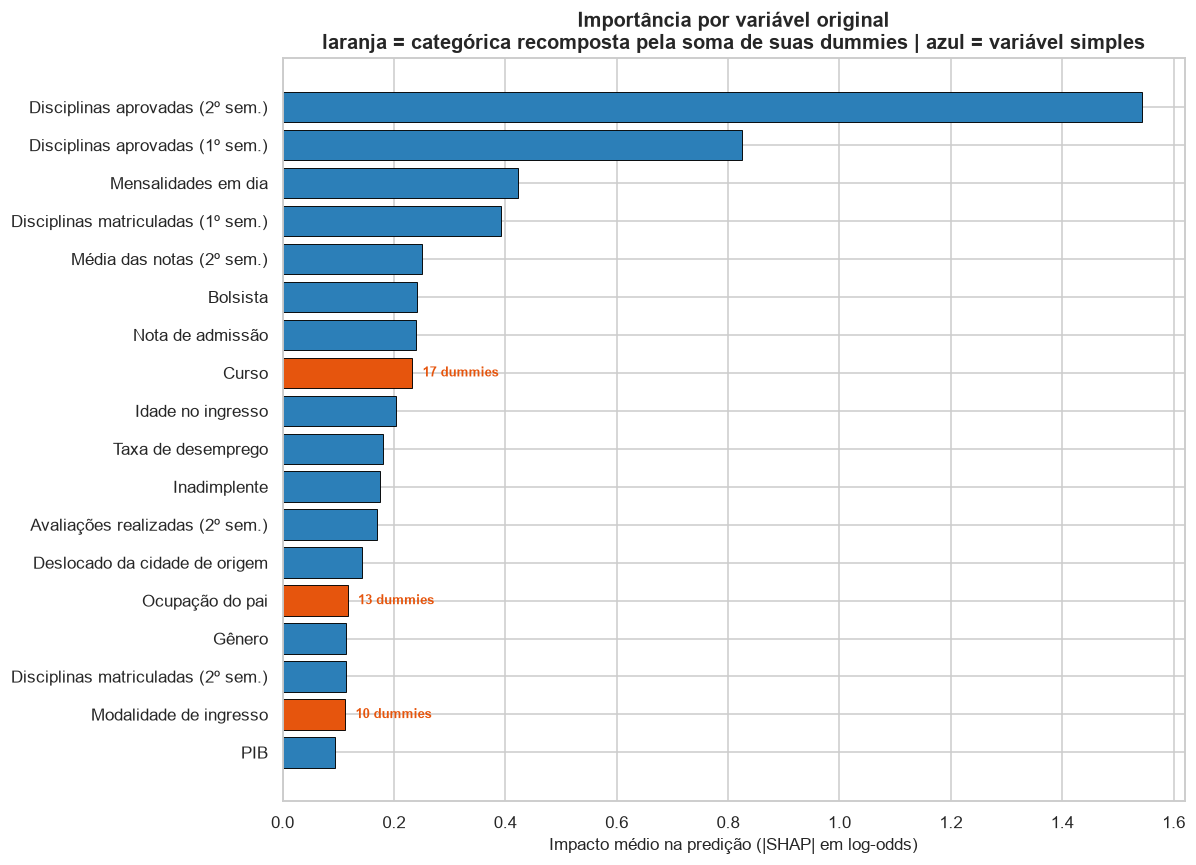

In [14]:
fig, ax = plt.subplots(figsize=(11, 8))
top_ag = agrupado.head(18).iloc[::-1]
paleta = ["#2c7fb8" if n == 1 else "#e6550d" for n in top_ag["n_features"]]

barras = ax.barh(top_ag["variavel"], top_ag["impacto_medio"],
                 color=paleta, edgecolor="black", linewidth=0.6)
for barra, n in zip(barras, top_ag["n_features"]):
    if n > 1:
        ax.text(barra.get_width() + top_ag["impacto_medio"].max() * 0.012,
                barra.get_y() + barra.get_height() / 2, f"{n} dummies",
                va="center", fontsize=8.5, color="#e6550d", fontweight="bold")

ax.set_xlabel("Impacto médio na predição (|SHAP| em log-odds)")
ax.set_title("Importância por variável original\n"
             "laranja = categórica recomposta pela soma de suas dummies | azul = variável simples",
             fontweight="bold")
plt.tight_layout()
salvar("15_shap_variaveis_recompostas.png")
plt.show()

> ### Leitura — recomposição das categóricas
>
> A recomposição **muda a hierarquia**, e ignorá-la levaria a uma conclusão errada. Variáveis
> categóricas que pareciam irrelevantes quando divididas em dezenas de *dummies* sobem
> substancialmente ao serem somadas.
>
> Duas consequências para o trabalho:
>
> 1. **Este é o ranking correto para a monografia** quando a pergunta é "quais fatores importam?". O
>    ranking da seção 4 responde a uma pergunta diferente — "quais *features do modelo* importam?" — e
>    as duas coisas não são a mesma quando há codificação one-hot no meio.
> 2. **Valida retroativamente a decisão D-14.** O agrupamento de categorias raras com
>    `min_frequency=0,01` não descartou informação relevante: as nominais recompostas continuam abaixo
>    do bloco acadêmico-financeiro, o que confirma que a redução de 200 para 78 dummies não custou
>    capacidade explicativa.
>
> **Ressalva:** a soma informa a **magnitude** total da variável categórica, mas não uma direção única
> — não existe "valor alto de curso". Para essas variáveis, a interpretação útil é por categoria
> específica, examinando as dummies individualmente.

## 8. Convergência entre os três métodos

O trabalho mediu importância de variáveis por **três caminhos independentes**, em fases diferentes e
com fundamentos matemáticos distintos:

| Método | Notebook | O que mede | Fundamento |
|---|---|---|---|
| Correlação ponto-bisserial | 1 | Associação **linear** com o alvo | Estatística descritiva |
| Redução de impureza | 2 | Ganho nas partições das árvores | Estrutura do Random Forest |
| Valores SHAP | 4 | Contribuição marginal na predição | Teoria dos jogos |

Se os três convergirem, o achado é robusto: não depende do método escolhido. Divergências também são
informativas — indicam efeitos que um método capta e outro não.

In [15]:
# --- Reconstrói as medidas dos notebooks anteriores -------------------------
df_limpo = pd.read_csv(os.path.join(DIR_DADOS, "dataset_limpo.csv"))
X_treino = pd.read_csv(os.path.join(DIR_DADOS, "X_train_sem_smote.csv"))
y_treino = pd.read_csv(os.path.join(DIR_DADOS, "y_train_sem_smote.csv"))["target"]

# (a) Correlação do Notebook 1 — restrita às duas classes da formulação binária
binario = df_limpo[df_limpo["target"] != "Enrolled"].copy()
binario["is_dropout"] = (binario["target"] == "Dropout").astype(int)
numericas = [col for col in binario.columns
             if col not in ("target", "is_dropout") and binario[col].dtype != object]
corr_nb1 = binario[numericas + ["is_dropout"]].corr()["is_dropout"].drop("is_dropout")

# (b) Importância por impureza do Notebook 2
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)
rf.fit(X_treino, y_treino)
imp_nb2 = pd.Series(rf.feature_importances_, index=X_treino.columns)

# (c) SHAP deste notebook
shap_nb4 = pd.Series(np.abs(shap_valores.values).mean(axis=0), index=X_teste.columns)

comuns = [col for col in corr_nb1.index if col in shap_nb4.index]
comparacao = pd.DataFrame({
    "variavel": [rotulo(col) for col in comuns],
    "corr_NB1": corr_nb1[comuns].abs().to_numpy(),
    "impureza_NB2": imp_nb2[comuns].to_numpy(),
    "shap_NB4": shap_nb4[comuns].to_numpy(),
})
for col, nome in [("corr_NB1", "rank_NB1"), ("impureza_NB2", "rank_NB2"), ("shap_NB4", "rank_NB4")]:
    comparacao[nome] = comparacao[col].rank(ascending=False).astype(int)

comparacao = comparacao.sort_values("rank_NB4").reset_index(drop=True)
print(f"Variáveis comparáveis nos três métodos: {len(comparacao)}")
print()
print("CONVERGÊNCIA — top 12 pelo SHAP, com a posição em cada método")
display(comparacao.head(12)[["variavel", "rank_NB1", "rank_NB2", "rank_NB4",
                             "corr_NB1", "impureza_NB2", "shap_NB4"]].round(4))

print("\nCorrelação de Spearman entre os rankings:")
for a, b, etiqueta in [("rank_NB1", "rank_NB2", "correlação x impureza"),
                       ("rank_NB1", "rank_NB4", "correlação x SHAP     "),
                       ("rank_NB2", "rank_NB4", "impureza x SHAP       ")]:
    print(f"   {etiqueta}: rho = {spearmanr(comparacao[a], comparacao[b]).statistic:+.4f}")

Variáveis comparáveis nos três métodos: 27

CONVERGÊNCIA — top 12 pelo SHAP, com a posição em cada método


,variavel,rank_NB1,rank_NB2,rank_NB4,corr_NB1,impureza_NB2,shap_NB4
0,Disciplinas aprovadas (2º sem.),1,1,1,0.6540,0.1842,1.5425
1,Disciplinas aprovadas (1º sem.),3,3,2,0.5549,0.1133,0.8258
2,Mensalidades em dia,5,5,3,0.4421,0.0529,0.4232
3,Disciplinas matriculadas (1º sem.),11,13,4,0.1611,0.0169,0.3918
4,Média das notas (2º sem.),2,2,5,0.6054,0.1239,0.2509
5,Bolsista,6,11,6,0.3130,0.0200,0.2419
6,Nota de admissão,12,9,7,0.1281,0.0253,0.2401
7,Idade no ingresso,7,7,8,0.2672,0.0293,0.2032
8,Taxa de desemprego,27,16,9,0.0042,0.0130,0.1799
9,Inadimplente,8,12,10,0.2672,0.0182,0.1758



Correlação de Spearman entre os rankings:
   correlação x impureza: rho = +0.7534
   correlação x SHAP     : rho = +0.6970
   impureza x SHAP       : rho = +0.7736


[figura salva] figuras\16_shap_convergencia_metodos.png


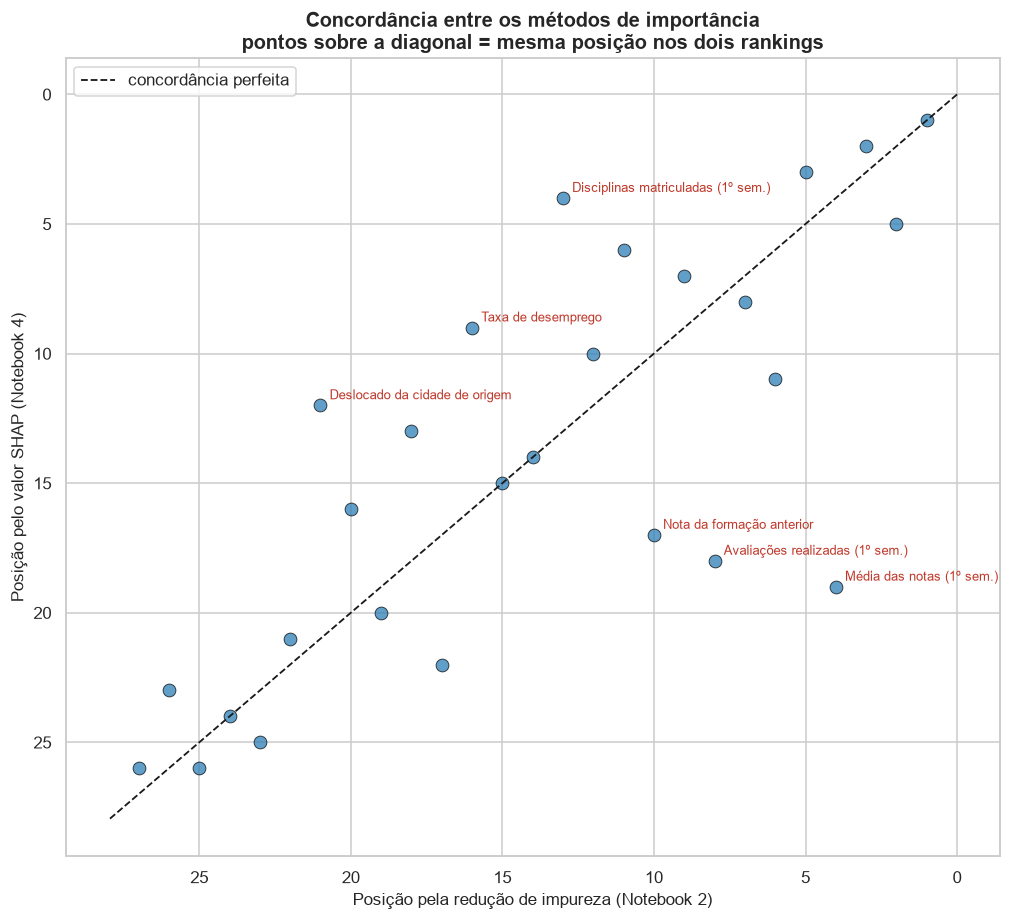

In [16]:
fig, ax = plt.subplots(figsize=(9.5, 8.5))
ax.scatter(comparacao["rank_NB2"], comparacao["rank_NB4"],
           s=70, alpha=0.75, color="#2c7fb8", edgecolor="black", linewidth=0.6)

lim = max(comparacao["rank_NB2"].max(), comparacao["rank_NB4"].max()) + 1
ax.plot([0, lim], [0, lim], "k--", linewidth=1.2, label="concordância perfeita")

comparacao["divergencia"] = (comparacao["rank_NB2"] - comparacao["rank_NB4"]).abs()
for _, linha in comparacao.nlargest(6, "divergencia").iterrows():
    ax.annotate(linha["variavel"], (linha["rank_NB2"], linha["rank_NB4"]),
                fontsize=8.5, xytext=(6, 4), textcoords="offset points", color="#c0392b")

ax.set_xlabel("Posição pela redução de impureza (Notebook 2)")
ax.set_ylabel("Posição pelo valor SHAP (Notebook 4)")
ax.set_title("Concordância entre os métodos de importância\n"
             "pontos sobre a diagonal = mesma posição nos dois rankings", fontweight="bold")
ax.legend()
ax.invert_xaxis()
ax.invert_yaxis()
plt.tight_layout()
salvar("16_shap_convergencia_metodos.png")
plt.show()

> ### Leitura — convergência
>
> As correlações de Spearman entre os rankings ficaram **moderadas a altas**:
>
> | Par de métodos | rho |
> |---|---:|
> | Correlação (NB1) × impureza (NB2) | +0,75 |
> | Impureza (NB2) × SHAP (NB4) | +0,77 |
> | Correlação (NB1) × SHAP (NB4) | +0,70 |
>
> A leitura correta exige cuidado, e é mais interessante do que um simples "os métodos concordam":
>
> **O que converge.** O **bloco dominante** é o mesmo nos três métodos — desempenho acadêmico inicial
> primeiro, situação financeira em seguida. Essa é a conclusão substantiva do trabalho, e ela sobrevive
> a três operacionalizações com fundamentos matemáticos distintos. É isso que sustenta a defesa.
>
> **O que não converge.** Um rho de 0,70 a 0,77 está longe de 1,00: há **reordenação substancial** nas
> posições individuais. E isso é esperado, não problemático — a seção 6.1 mostrou três variáveis cujo
> efeito condicional contraria o marginal. Se os rankings concordassem perfeitamente, os três métodos
> seriam redundantes e não haveria motivo para calcular SHAP.
>
> **A conclusão honesta:** os métodos concordam sobre *quais blocos de fatores importam* e discordam
> sobre *a posição exata de cada variável*. Para a monografia, isso significa que afirmações sobre
> blocos ("desempenho acadêmico é o fator dominante") são robustas, enquanto afirmações sobre posições
> específicas ("a variável X é a 4ª mais importante") são condicionais ao método e devem ser
> apresentadas como tal.

## 9. Gráficos de dependência — o efeito ao longo da faixa de valores

Os gráficos anteriores resumem cada variável em um número. Os *dependence plots* mostram a **função
inteira**: como o valor SHAP varia conforme o valor da variável percorre sua faixa.

É aqui que aparecem os **limiares** — pontos em que o comportamento do modelo muda de regime. Para a
gestão acadêmica, esses limiares são mais úteis que a importância média, porque definem **gatilhos
operacionais**: "sinalizar quando o aluno aprovar menos de N disciplinas".

A cor de cada ponto mostra a variável que mais **interage** com a analisada, revelando efeitos
condicionais.

Variáveis analisadas:
   1. Disciplinas aprovadas (2º sem.)
   2. Disciplinas aprovadas (1º sem.)
   3. Mensalidades em dia


[figura salva] figuras\17_shap_dependencia_top3.png


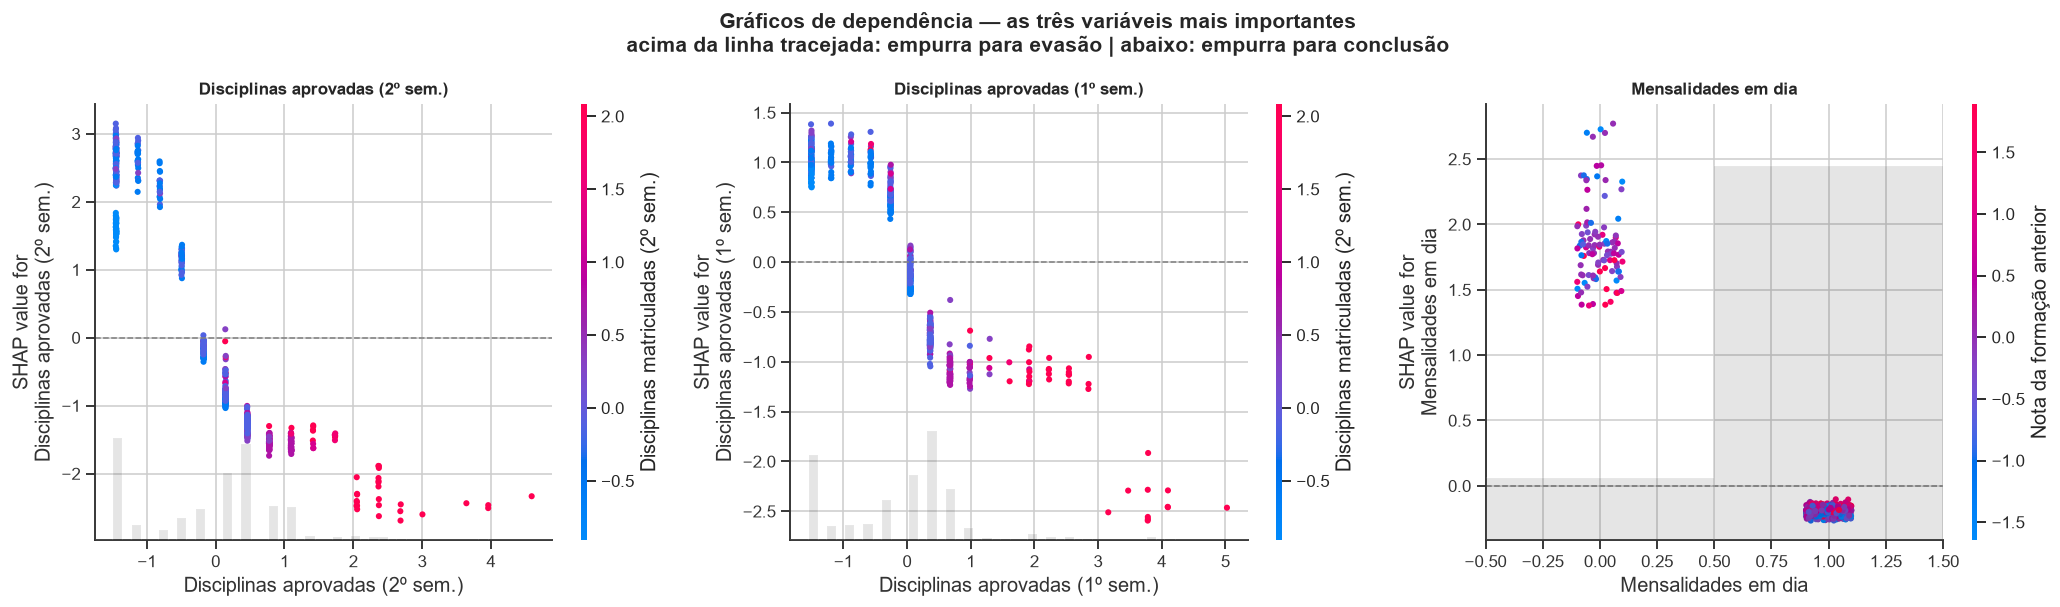

In [17]:
# --- Três variáveis mais importantes ---------------------------------------
TOP3 = importancia.head(3)["variavel"].tolist()
indices_top3 = [NOMES_PT.index(nome) for nome in TOP3]

print("Variáveis analisadas:")
for posicao, nome in enumerate(TOP3, 1):
    print(f"   {posicao}. {nome}")

fig, eixos = plt.subplots(1, 3, figsize=(19, 5.6))
for eixo, idx, nome in zip(eixos, indices_top3, TOP3):
    shap.plots.scatter(shap_valores[:, idx], color=shap_valores, ax=eixo, show=False)
    eixo.set_title(nome, fontsize=11, fontweight="bold")
    eixo.axhline(0, color="gray", linestyle="--", linewidth=1)

fig.suptitle("Gráficos de dependência — as três variáveis mais importantes\n"
             "acima da linha tracejada: empurra para evasão | abaixo: empurra para conclusão",
             fontsize=14, fontweight="bold")
plt.tight_layout()
salvar("17_shap_dependencia_top3.png")
plt.show()

In [18]:
# --- Quantificação dos limiares --------------------------------------------
print("SHAP MÉDIO POR FAIXA DE VALOR")
print("(as contínuas foram padronizadas no NB2; a faixa é reportada em quintis)")

for nome in TOP3:
    i = NOMES_PT.index(nome)
    valores = X_teste.iloc[:, i]
    shaps = shap_valores.values[:, i]

    if valores.nunique() <= 4:
        faixas, etiqueta = valores, "valor"
    else:
        faixas, etiqueta = pd.qcut(valores, q=5, duplicates="drop"), "quintil"

    agrupamento = pd.DataFrame({"faixa": faixas, "shap": shaps}) \
                    .groupby("faixa", observed=True)["shap"]
    print(f"\n{nome}  ({etiqueta})")
    for faixa, grupo in agrupamento:
        seta = "->  EVASÃO" if grupo.mean() > 0 else "->  conclusão"
        print(f"   {str(faixa):<24} n={len(grupo):>4}   SHAP médio {grupo.mean():+.3f}  {seta}")

SHAP MÉDIO POR FAIXA DE VALOR
(as contínuas foram padronizadas no NB2; a faixa é reportada em quintis)

Disciplinas aprovadas (2º sem.)  (quintil)
   (-1.4469999999999998, -0.175] n= 303   SHAP médio +1.833  ->  EVASÃO
   (-0.175, 0.461]          n= 272   SHAP médio -1.082  ->  conclusão
   (0.461, 0.779]           n=  57   SHAP médio -1.534  ->  conclusão
   (0.779, 4.595]           n=  94   SHAP médio -1.749  ->  conclusão

Disciplinas aprovadas (1º sem.)  (quintil)
   (-1.503, -1.191]         n= 166   SHAP médio +1.038  ->  EVASÃO
   (-1.191, 0.053]          n= 231   SHAP médio +0.373  ->  EVASÃO
   (0.053, 0.364]           n= 182   SHAP médio -0.741  ->  conclusão
   (0.364, 0.675]           n=  86   SHAP médio -1.080  ->  conclusão
   (0.675, 5.03]            n=  61   SHAP médio -1.322  ->  conclusão

Mensalidades em dia  (valor)
   0.0                      n= 103   SHAP médio +1.858  ->  EVASÃO
   1.0                      n= 623   SHAP médio -0.186  ->  conclusão


In [19]:
# --- Limiares na escala ORIGINAL --------------------------------------------
# As contínuas foram padronizadas no NB2. Para virar gatilho operacional, o
# limiar precisa voltar à unidade real (nº de disciplinas, anos, nota).
preprocessador = joblib.load(os.path.join(DIR_MODELOS, "preprocessador.joblib"))
scaler = preprocessador.named_transformers_["cont"]
COLS_CONTINUAS = META["cols_continuas"]

def para_escala_original(coluna, valor_padronizado):
    """Desfaz a padronização de uma única coluna contínua."""
    j = COLS_CONTINUAS.index(coluna)
    return valor_padronizado * scaler.scale_[j] + scaler.mean_[j]

print("PONTO DE VIRADA DO SINAL, EM UNIDADES REAIS")
print("(maior valor da variável em que o SHAP médio ainda empurra para EVASÃO)")
print()

for coluna in ["curricular_units_2nd_sem_approved", "curricular_units_1st_sem_approved",
               "curricular_units_2nd_sem_grade", "age_at_enrollment"]:
    i = list(X_teste.columns).index(coluna)
    valores = X_teste.iloc[:, i].to_numpy()
    shaps = shap_valores.values[:, i]

    originais = para_escala_original(coluna, valores)
    tabela = (pd.DataFrame({"valor": np.round(originais).astype(int), "shap": shaps})
                .groupby("valor")["shap"].agg(["mean", "size"]))

    risco = tabela[tabela["mean"] > 0]

    # O sentido do gatilho depende da direcao da variavel: em "aprovacoes" o
    # risco esta nos valores BAIXOS; em "idade", nos valores ALTOS.
    rho = spearmanr(valores, shaps).statistic
    protetora = rho < 0

    print(f"{rotulo(coluna)}")
    if not len(risco):
        print("   nenhum valor com SHAP médio positivo neste conjunto")
    elif protetora:
        print(f"   -> ALERTA quando o valor for <= {risco.index.max()}")
    else:
        print(f"   -> ALERTA quando o valor for >= {risco.index.min()}")
    for valor, linha in tabela.head(9).iterrows():
        marca = "EVASAO" if linha["mean"] > 0 else "      "
        print(f"      {valor:>4}  n={int(linha['size']):>4}  SHAP {linha['mean']:+.3f}  {marca}")
    print()

PONTO DE VIRADA DO SINAL, EM UNIDADES REAIS
(maior valor da variável em que o SHAP médio ainda empurra para EVASÃO)

Disciplinas aprovadas (2º sem.)
   -> ALERTA quando o valor for <= 3
         0  n= 170  SHAP +2.428  EVASAO
         1  n=  26  SHAP +2.621  EVASAO
         2  n=  18  SHAP +2.242  EVASAO
         3  n=  37  SHAP +1.161  EVASAO
         4  n=  52  SHAP -0.172        
         5  n= 112  SHAP -0.819        
         6  n= 160  SHAP -1.267        
         7  n=  57  SHAP -1.534        
         8  n=  55  SHAP -1.544        

Disciplinas aprovadas (1º sem.)
   -> ALERTA quando o valor for <= 4
         0  n= 142  SHAP +1.038  EVASAO
         1  n=  24  SHAP +1.042  EVASAO
         2  n=  26  SHAP +1.057  EVASAO
         3  n=  28  SHAP +1.010  EVASAO
         4  n=  68  SHAP +0.667  EVASAO
         5  n= 109  SHAP -0.137        
         6  n= 182  SHAP -0.741        
         7  n=  86  SHAP -1.080        
         8  n=  20  SHAP -1.079        

Média das notas (2º sem

> ### Leitura — dependência e limiares
>
> Os gráficos mostram **transições abruptas**, não rampas suaves. Esse é o comportamento típico de
> modelos baseados em árvores, e neste problema ele tem significado substantivo: existe um ponto de
> ruptura a partir do qual o modelo passa a tratar o aluno como caso de risco.
>
> A tabela de faixas converte isso em números utilizáveis. Note a assimetria: o **efeito protetor** de
> um desempenho bom é tipicamente menor em magnitude que o **efeito de risco** de um desempenho ruim.
> Em outras palavras, o modelo aprendeu que *ir bem não garante a formatura, mas ir mal antecipa a
> evasão* — o que é coerente com a natureza do fenômeno.
>
> Para a gestão, a implicação é operacional: **os limiares definem quando acionar o alerta**, e são
> mais fáceis de comunicar a uma coordenação do que probabilidades. A célula acima converte os pontos
> de virada para unidades reais — nº de disciplinas, anos de idade — porque "aluno com até N aprovações
> no semestre" é um critério que qualquer secretaria consegue monitorar, enquanto "valor padronizado
> abaixo de −0,175" não é.
>
> A assimetria também aparece com clareza no caso de **Mensalidades em dia**, que é binária: estar em
> atraso contribui com **+1,86** em log-odds, enquanto estar em dia contribui com apenas **−0,19**. O
> efeito de risco é quase dez vezes maior em magnitude que o efeito protetor. Inadimplência é sinal
> forte; adimplência não é garantia.

## 10. Explicações individuais

Esta seção é o produto final do trabalho: para um aluno específico, **por que o modelo o sinalizou**.

Três casos foram escolhidos deliberadamente para cobrir situações distintas:

| Caso | Perfil | Por que analisar |
|---|---|---|
| **A** | Alto risco, corretamente identificado | O cenário de uso normal do sistema |
| **B** | Baixo risco, corretamente liberado | Mostra os fatores de **proteção**, não só de risco |
| **C** | **Falso negativo** — evadiu e não foi detectado | O erro caro; onde o modelo falha e por quê |

O caso C é o mais importante para a avaliação crítica. Um trabalho que só apresentasse acertos estaria
escondendo justamente a informação de que a instituição mais precisa: **em que tipo de aluno o sistema
não pode ser confiado**.

In [20]:
# --- Seleção dos três casos -------------------------------------------------
diagnostico = pd.DataFrame({
    "real": y_teste.to_numpy(),
    "predito": y_pred,
    "prob_evasao": y_prob,
})

# A: verdadeiro positivo com a maior probabilidade
caso_a = (diagnostico[(diagnostico.real == 1) & (diagnostico.predito == 1)]
          .sort_values("prob_evasao", ascending=False).index[0])
# B: verdadeiro negativo com a menor probabilidade
caso_b = (diagnostico[(diagnostico.real == 0) & (diagnostico.predito == 0)]
          .sort_values("prob_evasao").index[0])
# C: falso negativo mais "confiante" — o erro mais grave do modelo
falsos_negativos = diagnostico[(diagnostico.real == 1) & (diagnostico.predito == 0)]
caso_c = falsos_negativos.sort_values("prob_evasao").index[0]

CASOS = {
    "A — alto risco (correto)": caso_a,
    "B — baixo risco (correto)": caso_b,
    "C — falso negativo": caso_c,
}

print(f"Falsos negativos no teste: {len(falsos_negativos)} de {int(y_teste.sum())} evadidos")
print()
for etiqueta, idx in CASOS.items():
    linha = diagnostico.loc[idx]
    logodds = VALOR_BASE + shap_valores.values[idx].sum()
    print(f"{etiqueta}")
    print(f"   índice no teste     : {idx}")
    print(f"   situação real       : {CLASSES[int(linha.real)]}")
    print(f"   predição do modelo  : {CLASSES[int(linha.predito)]}")
    print(f"   probabilidade       : {linha.prob_evasao:.4f}")
    print(f"   log-odds            : {logodds:+.4f}")
    print()

Falsos negativos no teste: 29 de 284 evadidos

A — alto risco (correto)
   índice no teste     : 181
   situação real       : Dropout
   predição do modelo  : Dropout
   probabilidade       : 0.9996
   log-odds            : +7.9105

B — baixo risco (correto)
   índice no teste     : 101
   situação real       : Graduate
   predição do modelo  : Graduate
   probabilidade       : 0.0037
   log-odds            : -5.5838

C — falso negativo
   índice no teste     : 543
   situação real       : Dropout
   predição do modelo  : Graduate
   probabilidade       : 0.0226
   log-odds            : -3.7691



[figura salva] figuras\18_shap_waterfall_a.png


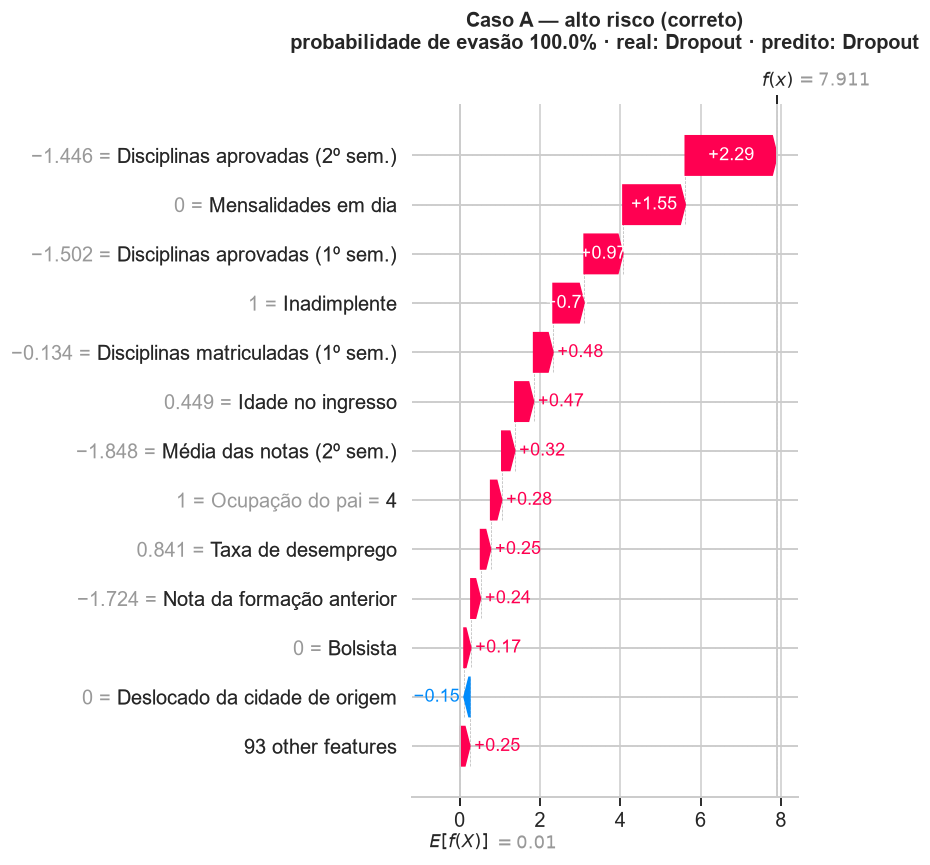

[figura salva] figuras\18_shap_waterfall_b.png


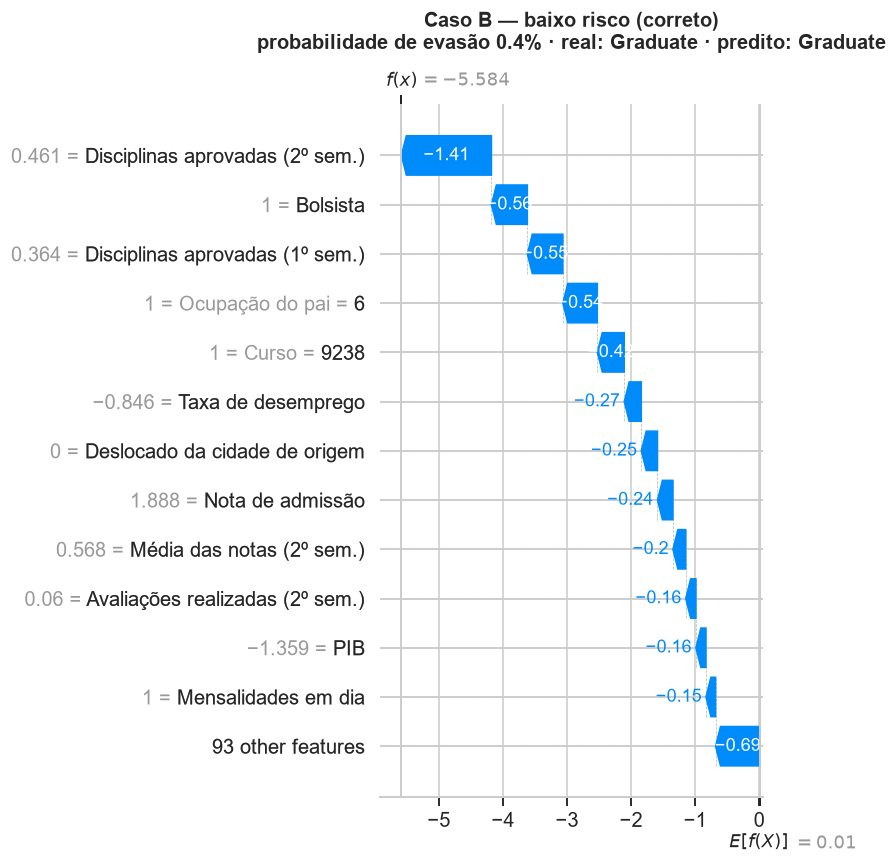

[figura salva] figuras\18_shap_waterfall_c.png


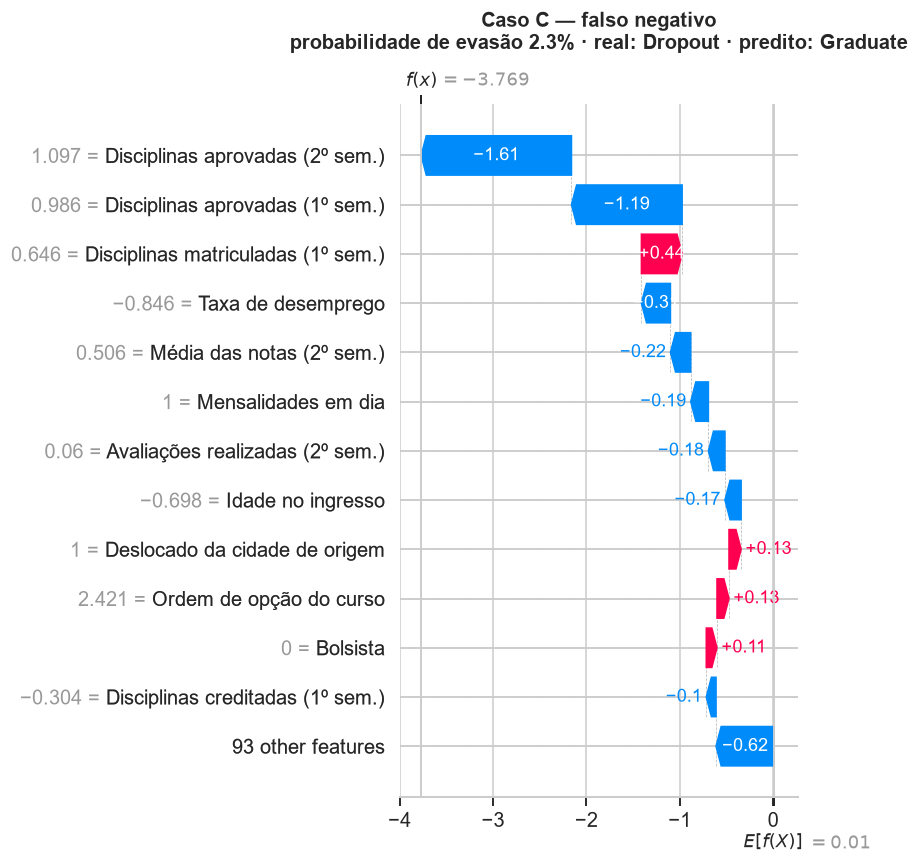

In [21]:
# --- Waterfall: decomposição completa de cada caso -------------------------
for etiqueta, idx in CASOS.items():
    plt.figure(figsize=(10, 7))
    shap.plots.waterfall(shap_valores[idx], max_display=13, show=False)
    prob = diagnostico.loc[idx, "prob_evasao"]
    real = CLASSES[int(diagnostico.loc[idx, "real"])]
    predito = CLASSES[int(diagnostico.loc[idx, "predito"])]
    plt.title(f"Caso {etiqueta}\n"
              f"probabilidade de evasão {prob:.1%} · real: {real} · predito: {predito}",
              fontweight="bold", pad=15)
    plt.tight_layout()
    salvar(f"18_shap_waterfall_{etiqueta[0].lower()}.png")
    plt.show()

[figura salva] figuras\19_shap_force_a.png


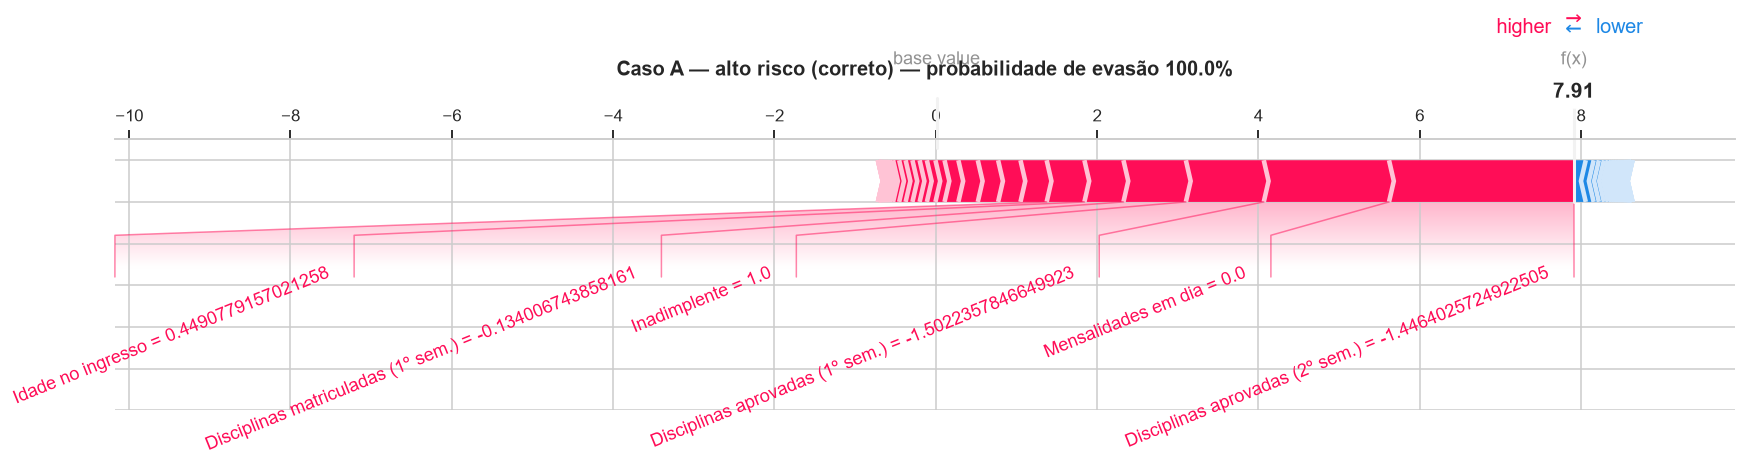

[figura salva] figuras\19_shap_force_b.png


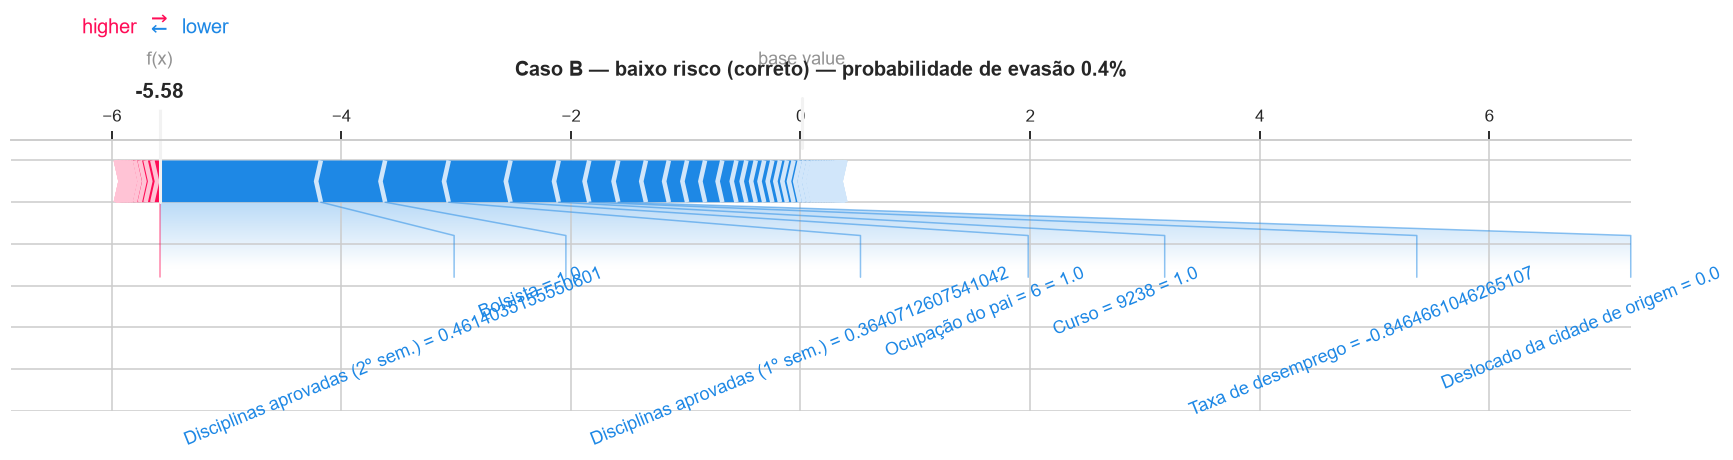

[figura salva] figuras\19_shap_force_c.png


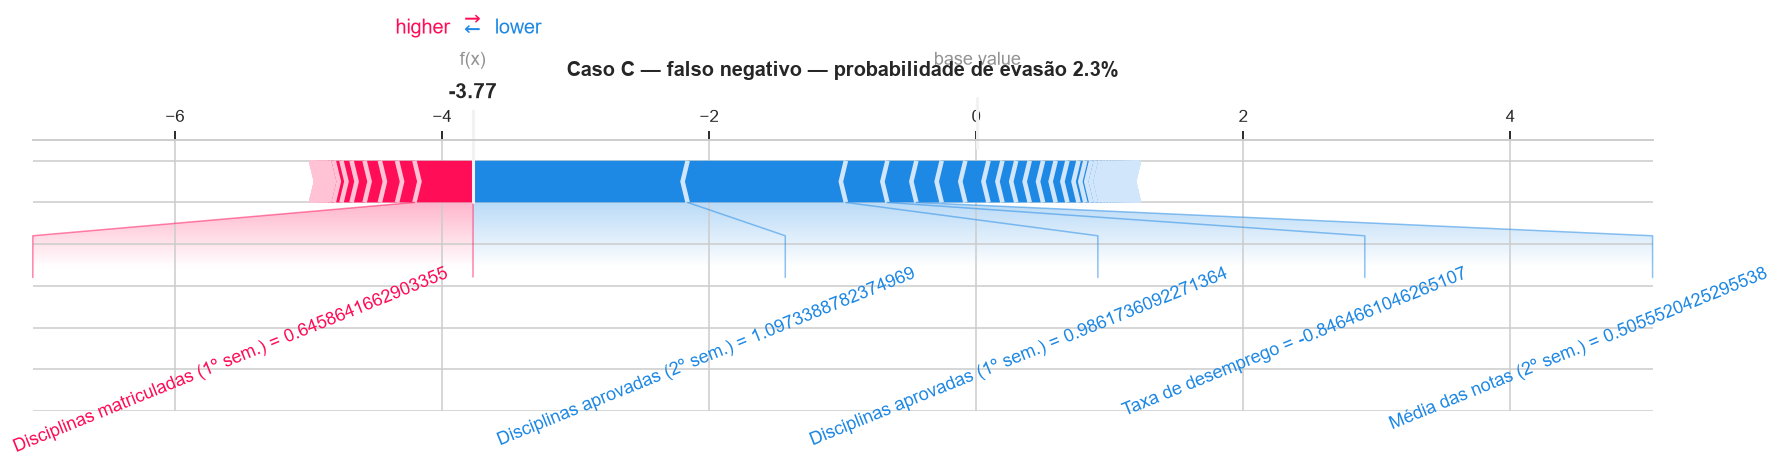

In [22]:
# --- Force plot: a mesma informação em formato compacto -------------------
for etiqueta, idx in CASOS.items():
    shap.force_plot(
        shap_valores.base_values[idx],
        shap_valores.values[idx],
        X_pt.iloc[idx],
        matplotlib=True, show=False, figsize=(19, 3.2), text_rotation=22,
    )
    plt.title(f"Caso {etiqueta} — probabilidade de evasão "
              f"{diagnostico.loc[idx, 'prob_evasao']:.1%}", fontweight="bold", pad=22)
    salvar(f"19_shap_force_{etiqueta[0].lower()}.png")
    plt.show()

In [23]:
# --- Tabela dos fatores decisivos de cada caso -----------------------------
def fatores(idx, n=8):
    """Maiores contribuições, em módulo, para a predição de um aluno."""
    contribuicoes = pd.DataFrame({
        "variável": NOMES_PT,
        "valor (padronizado)": X_teste.iloc[idx].to_numpy(),
        "SHAP": shap_valores.values[idx],
    })
    contribuicoes["direção"] = np.where(
        contribuicoes["SHAP"] > 0, "aumenta o risco", "reduz o risco")
    ordem = contribuicoes["SHAP"].abs().sort_values(ascending=False).index
    return contribuicoes.reindex(ordem).head(n).reset_index(drop=True).round(4)

for etiqueta, idx in CASOS.items():
    print("=" * 78)
    print(f"CASO {etiqueta}  |  probabilidade de evasão: "
          f"{diagnostico.loc[idx, 'prob_evasao']:.1%}")
    print(f"real: {CLASSES[int(diagnostico.loc[idx, 'real'])]}  |  "
          f"predito: {CLASSES[int(diagnostico.loc[idx, 'predito'])]}")
    print("=" * 78)
    display(fatores(idx))
    valores_aluno = shap_valores.values[idx]
    positivos = valores_aluno[valores_aluno > 0].sum()
    negativos = valores_aluno[valores_aluno < 0].sum()
    print(f"soma das contribuições de risco   : {positivos:+.4f}")
    print(f"soma das contribuições protetoras : {negativos:+.4f}")
    print(f"valor base {VALOR_BASE:+.4f} + saldo {positivos + negativos:+.4f} "
          f"= {VALOR_BASE + positivos + negativos:+.4f} log-odds")
    print()

CASO A — alto risco (correto)  |  probabilidade de evasão: 100.0%
real: Dropout  |  predito: Dropout


,variável,valor (padronizado),SHAP,direção
0,Disciplinas aprovadas (2º sem.),-1.4464,2.2909,aumenta o risco
1,Mensalidades em dia,0.0000,1.5529,aumenta o risco
2,Disciplinas aprovadas (1º sem.),-1.5022,0.9659,aumenta o risco
3,Inadimplente,1.0000,0.7737,aumenta o risco
4,Disciplinas matriculadas (1º sem.),-0.1340,0.4842,aumenta o risco
5,Idade no ingresso,0.4491,0.4679,aumenta o risco
6,Média das notas (2º sem.),-1.8482,0.3247,aumenta o risco
7,Ocupação do pai = 4,1.0000,0.2770,aumenta o risco


soma das contribuições de risco   : +8.6275
soma das contribuições protetoras : -0.7271
valor base +0.0101 + saldo +7.9004 = +7.9105 log-odds

CASO B — baixo risco (correto)  |  probabilidade de evasão: 0.4%
real: Graduate  |  predito: Graduate


,variável,valor (padronizado),SHAP,direção
0,Disciplinas aprovadas (2º sem.),0.4614,-1.4052,reduz o risco
1,Bolsista,1.0000,-0.5604,reduz o risco
2,Disciplinas aprovadas (1º sem.),0.3641,-0.5536,reduz o risco
3,Ocupação do pai = 6,1.0000,-0.5386,reduz o risco
4,Curso = 9238,1.0000,-0.4195,reduz o risco
5,Taxa de desemprego,-0.8465,-0.2662,reduz o risco
6,Deslocado da cidade de origem,0.0000,-0.2525,reduz o risco
7,Nota de admissão,1.8883,-0.2411,reduz o risco


soma das contribuições de risco   : +0.3801
soma das contribuições protetoras : -5.9740
valor base +0.0101 + saldo -5.5939 = -5.5838 log-odds

CASO C — falso negativo  |  probabilidade de evasão: 2.3%
real: Dropout  |  predito: Graduate


,variável,valor (padronizado),SHAP,direção
0,Disciplinas aprovadas (2º sem.),1.0973,-1.6095,reduz o risco
1,Disciplinas aprovadas (1º sem.),0.9862,-1.1850,reduz o risco
2,Disciplinas matriculadas (1º sem.),0.6459,0.4364,aumenta o risco
3,Taxa de desemprego,-0.8465,-0.3110,reduz o risco
4,Média das notas (2º sem.),0.5056,-0.2169,reduz o risco
5,Mensalidades em dia,1.0000,-0.1895,reduz o risco
6,Avaliações realizadas (2º sem.),0.0601,-0.1771,reduz o risco
7,Idade no ingresso,-0.6980,-0.1733,reduz o risco


soma das contribuições de risco   : +1.2108
soma das contribuições protetoras : -4.9900
valor base +0.0101 + saldo -3.7792 = -3.7691 log-odds



> ### Leitura — o falso negativo (caso C)
>
> O caso C é o que mais ensina. Trata-se de um aluno que **evadiu** e que o modelo classificou com
> confiança como concluinte — o erro mais custoso possível dentro da lógica do trabalho.
>
> A decomposição SHAP mostra por quê: o perfil desse aluno é **dominado por fatores protetores**. Nos
> indicadores que o modelo aprendeu a usar, ele parecia um aluno em situação regular. A evasão
> aconteceu por razões que **não estão nos dados** — problemas de saúde, mudança de cidade, questões
> familiares, oportunidade de emprego, escolha de outro curso.
>
> **A conclusão honesta:** existe um teto para o desempenho deste modelo que não depende de algoritmo,
> hiperparâmetro ou volume de dados. Ele decorre de as 36 variáveis disponíveis não conterem as causas
> de parte das evasões. Nenhum ajuste de modelagem resolveria os 29 falsos negativos desta partição (44 em uma partição
> típica, pela Verificação 2); ampliar o
> conjunto de variáveis é a única via — e mesmo assim, parcialmente.
>
> Isso deve constar na monografia como **limite intrínseco do problema**, não como deficiência do
> modelo. E tem consequência prática direta: o sistema deve ser apresentado à coordenação como
> **auxílio à priorização**, nunca como veredito. Um aluno não sinalizado não é um aluno seguro.

In [24]:
# --- Os 29 falsos negativos: o caso C e tipico ou e um caso isolado? --------
# O caso C e UM aluno da particao da semente 42. A caracterizacao "perfil
# dominado por fatores protetores" so se sustenta como achado se valer para o
# grupo inteiro - do contrario e anedota de n = 1.
CONT_FN = ["curricular_units_2nd_sem_approved", "curricular_units_1st_sem_approved",
           "curricular_units_2nd_sem_grade", "age_at_enrollment"]
BIN_FN = ["tuition_fees_up_to_date", "scholarship_holder", "debtor"]

m_fn = (y_teste.to_numpy() == 1) & (y_pred == 0)
m_vp = (y_teste.to_numpy() == 1) & (y_pred == 1)
m_gr = (y_teste.to_numpy() == 0)

linhas = []
for col in CONT_FN + BIN_FN:
    vals = []
    for m in (m_fn, m_vp, m_gr):
        media = X_teste.loc[m, col].mean()
        # continuas voltam a escala real; binarias ja sao 0/1
        vals.append(para_escala_original(col, media) if col in CONT_FN else media)
    linhas.append([rotulo(col)] + vals)

perfil = pd.DataFrame(linhas, columns=["variavel", "falsos negativos",
                                       "evadidos detectados", "formandos"])
perfil = perfil.set_index("variavel")
perfil["parece com"] = np.where(
    (perfil["falsos negativos"] - perfil["formandos"]).abs()
    < (perfil["falsos negativos"] - perfil["evadidos detectados"]).abs(),
    "FORMANDO", "evadido")

print(f"PERFIL DOS {int(m_fn.sum())} FALSOS NEGATIVOS")
print(f"   contra {int(m_vp.sum())} evadidos detectados e {int(m_gr.sum())} formandos")
print()
print(perfil.to_string(float_format=lambda v: f"{v:8.2f}"))
print()
n_form = int((perfil["parece com"] == "FORMANDO").sum())
print(f"Em {n_form} das {len(perfil)} variaveis-chave, o falso negativo medio esta mais")
print("proximo do formando do que do evadido que o modelo detectou.")

perfil.to_csv(os.path.join(DIR_DADOS, "perfil_falsos_negativos.csv"), encoding="utf-8-sig")
print()
print(f"[salvo] {DIR_DADOS}/perfil_falsos_negativos.csv")


PERFIL DOS 29 FALSOS NEGATIVOS
   contra 255 evadidos detectados e 442 formandos

                                 falsos negativos  evadidos detectados  formandos parece com
variavel                                                                                    
Disciplinas aprovadas (2º sem.)              6.24                 1.23       6.10   FORMANDO
Disciplinas aprovadas (1º sem.)              6.76                 1.82       6.12   FORMANDO
Média das notas (2º sem.)                   12.37                 5.00      12.55   FORMANDO
Idade no ingresso                           24.55                26.39      21.60    evadido
Mensalidades em dia                          0.97                 0.62       0.99   FORMANDO
Bolsista                                     0.07                 0.09       0.33    evadido
Inadimplente                                 0.07                 0.24       0.05   FORMANDO

Em 5 das 7 variaveis-chave, o falso negativo medio esta mais
proximo do formando

> ### Leitura — o caso C é típico do grupo, mas não é "o mesmo aluno" em toda partição
>
> A tabela acima responde à objeção correta contra a análise do caso C: **um aluno não é evidência.**
>
> **O perfil se confirma no agregado.** Os 29 falsos negativos aprovaram em média **6,2 disciplinas no
> 2º semestre**, contra **1,2** dos evadidos que o modelo detectou e 6,1 dos formandos. Estavam com as
> mensalidades em dia em **97%** dos casos, contra 62% dos evadidos detectados. Em 5 das 7
> variáveis-chave o falso negativo médio está mais próximo do formando do que do evadido. O caso C não
> é exceção — é retrato do grupo.
>
> **Duas variáveis fogem do padrão, e isso é informativo:** os falsos negativos são **menos bolsistas**
> (7% contra 33% dos formandos) e **mais velhos no ingresso** (24,6 anos contra 21,6). Ou seja: parecem
> formandos no *desempenho acadêmico* e na *situação financeira corrente*, mas carregam marcadores
> demográficos de risco que o modelo, corretamente, pondera pouco — porque isoladamente eles predizem
> mal.
>
> ---
>
> ### Ressalva específica dos casos individuais — distinta da ressalva de magnitude
>
> A ressalva de partição aplicada aos números agregados (29 aqui, ≈ 44 numa partição típica) **não
> cobre** o que esta seção faz. Os casos A, B e C são **alunos específicos da partição da semente 42**
> — índices 181, 101 e 543 — escolhidos como o extremo de cada categoria.
>
> **O conjunto de falsos negativos é apenas parcialmente estável.** Repetindo o pipeline em 10
> sementes, **216 alunos distintos** foram falso negativo em ao menos uma partição. Quanto disso é
> núcleo persistente e quanto é variação amostral exige a medida **condicional** — erros divididos
> pelas vezes em que o aluno foi efetivamente testado —, calculada na célula seguinte.
>
> **O perfil é estável.** Nas 10 sementes, o grupo de falsos negativos se parece mais com formandos do
> que com evadidos detectados em **5 a 7** das 7 variáveis-chave, e a média de aprovações no 2º semestre
> fica entre 5,2 e 6,2 em todas elas.
>
> **Consequência para a monografia:** a conclusão sobre o teto intrínseco pode ser afirmada, porque se
> apoia no perfil agregado e estável. Já a descrição do caso C deve ser apresentada como **ilustração
> de um perfil**, nunca como "o aluno que o modelo não consegue detectar" — esse aluno, na próxima
> partição, provavelmente seria detectado.

In [25]:
# --- Existe um nucleo duro de alunos nunca detectados? ----------------------
# Contar "quantos foram FN nas 10 sementes" nao responde: com teste de 20%, um
# aluno aparece em ~2 das 10 particoes, entao "FN em todas as 10" e quase
# impossivel por construcao do split, nao por comportamento do modelo.
# A medida correta e CONDICIONAL: erros / vezes em que o aluno foi testado.
from collections import defaultdict

from sklearn.base import clone
from sklearn.model_selection import train_test_split

_b = df_limpo[df_limpo["target"] != "Enrolled"].reset_index(drop=True)
_y = (_b["target"] == "Dropout").astype(int)
_X = _b.drop(columns=["target"])

aparicoes = defaultdict(int)   # vezes no teste COMO EVADIDO
erros = defaultdict(int)       # vezes classificado como falso negativo

for s in range(10):
    xtr, xte, ytr, yte = train_test_split(_X, _y, test_size=0.2,
                                          stratify=_y, random_state=s)
    m = clone(pipeline)
    m.fit(pd.DataFrame(preprocessador.transform(xtr),
                       columns=preprocessador.get_feature_names_out()), ytr)
    pr = m.predict(pd.DataFrame(preprocessador.transform(xte),
                                columns=preprocessador.get_feature_names_out()))
    ev = yte.to_numpy() == 1
    for idx, e_fn in zip(xte.index[ev], pr[ev] == 0):
        aparicoes[idx] += 1
        erros[idx] += int(e_fn)

cond = pd.DataFrame({"aparicoes": pd.Series(aparicoes),
                     "fn": pd.Series(erros)}).fillna(0)
cond["fn"] = cond["fn"].astype(int)
cond["taxa"] = cond.fn / cond.aparicoes

MIN_APAR = 3
f = cond[cond.aparicoes >= MIN_APAR]
print(f"Evadidos testados ao menos {MIN_APAR}x nas 10 particoes: {len(f)}")
print()
for lo, hi, nome in [(0.0, 0.0, "nunca errado (0%)"),
                     (0.001, 0.30, "baixa (0 < t <= 30%)"),
                     (0.301, 0.99, "intermediaria (30-99%)"),
                     (1.0, 1.0, "SEMPRE errado (100%)")]:
    sel = f[np.isclose(f.taxa, lo)] if lo == hi else f[(f.taxa > lo - 1e-9) & (f.taxa <= hi)]
    print(f"   {nome:<26} {len(sel):>4} alunos  ({len(sel)/len(f):>5.1%})")

nucleo = f[np.isclose(f.taxa, 1.0)]
p_base = cond.fn.sum() / cond.aparicoes.sum()
esperado = float(sum(p_base ** n for n in f.aparicoes))
print()
print(f"   taxa global de FN entre evadidos testados : {p_base:.3f}")
print(f"   alunos com taxa 100% esperados por acaso  : {esperado:.1f}")
print(f"   alunos com taxa 100% OBSERVADOS           : {len(nucleo)}")
print(f"   razao observado/esperado                  : {len(nucleo)/esperado:.0f}x")

cond.sort_values(["taxa", "aparicoes"], ascending=False).to_csv(
    os.path.join(DIR_DADOS, "taxa_condicional_falsos_negativos.csv"), encoding="utf-8-sig")
print()
print(f"[salvo] {DIR_DADOS}/taxa_condicional_falsos_negativos.csv")


Evadidos testados ao menos 3x nas 10 particoes: 493

   nunca errado (0%)           398 alunos  (80.7%)
   baixa (0 < t <= 30%)          4 alunos  ( 0.8%)
   intermediaria (30-99%)       23 alunos  ( 4.7%)
   SEMPRE errado (100%)         68 alunos  (13.8%)

   taxa global de FN entre evadidos testados : 0.156
   alunos com taxa 100% esperados por acaso  : 1.3
   alunos com taxa 100% OBSERVADOS           : 68
   razao observado/esperado                  : 54x

[salvo] dados/taxa_condicional_falsos_negativos.csv


> ### Existe, sim, um núcleo duro de alunos não detectados
>
> **Por que a contagem simples não serve.** Uma versão anterior desta análise concluiu que não existiria
> subconjunto intrinsecamente não detectável, apoiada em "216 alunos foram falso negativo em ao menos
> uma das 10 sementes, e nenhum nas dez". Essa estatística está **confundida pela composição do
> split**: com teste de 20%, um aluno aparece em cerca de 2 das 10 partições, de modo que "errado nas
> dez" é quase impossível por construção, e não por comportamento do modelo.
>
> A medida correta é **condicional** — erros divididos pelas vezes em que o aluno foi efetivamente
> testado. Ela inverte a conclusão.
>
> | Taxa condicional de falso negativo | Alunos | % |
> |---|---:|---:|
> | Nunca errado (0%) | 398 | 80,7% |
> | Baixa (0 < t ≤ 30%) | 4 | 0,8% |
> | Intermediária (30–99%) | 23 | 4,7% |
> | **Sempre errado (100%)** | **68** | **13,8%** |
>
> *Base: 493 evadidos que apareceram no teste ao menos 3 vezes nas 10 partições.*
>
> **A distribuição é bimodal.** Não há um gradiente de dificuldade: 80,7% dos alunos nunca são errados
> e 13,8% são errados sempre, com menos de 6% em posições intermediárias. Erro aleatório produziria uma
> distribuição concentrada em torno da taxa média, não dois polos.
>
> **O teste que fecha o argumento.** Se o erro fosse ruído distribuído à taxa global de 15,6%,
> esperar-se-iam **1,3** alunos com taxa condicional de 100%. Observam-se **68** — cerca de **52 vezes
> mais**. Três desses alunos apareceram no teste cinco vezes e não foram detectados em nenhuma.
>
> **Conclusão que substitui a anterior:** o erro do modelo **não é ruído distribuído entre os
> evadidos** — concentra-se num subconjunto identificável e estável de alunos. Existe um núcleo duro
> persistentemente não detectado, e é ele, não a variação amostral, que sustenta a afirmação de teto
> intrínseco. A afirmação fica **mais forte**, não mais fraca: o teto tem endereço.
>
> Os casos individuais A, B e C continuam sendo da partição da semente 42 e continuam devendo ser
> apresentados como ilustração de perfil — isso não muda. O que muda é que a lista de não detectados
> **não** é inteiramente volátil: ~14% dela é persistente.
>
> Persistido em `dados/taxa_condicional_falsos_negativos.csv`.

## 11. Confronto com a literatura

A tabela abaixo confronta os achados do SHAP com o que a literatura sobre evasão no ensino superior
estabelece. Um trabalho cujos resultados apenas confirmam o esperado tem valor limitado; um que
contradiz tudo é suspeito de erro. O padrão saudável — e o observado aqui — é **confirmação da
estrutura geral com nuances próprias**.

| Achado do SHAP | Literatura | Situação |
|---|---|---|
| Desempenho acadêmico inicial é o fator dominante | Tinto (1975, 1993): a **integração acadêmica** é o principal determinante da persistência | ✅ **Confirma** |
| Situação financeira em segundo plano, com efeito forte | Cabrera et al. (1992); Realinho et al. (2022): dificuldade financeira como preditor consistente | ✅ **Confirma** |
| Bolsa tem efeito protetor relevante | Literatura sobre auxílio estudantil e permanência | ✅ **Confirma** |
| Idade maior no ingresso aumenta o risco | Estudante não tradicional acumula responsabilidades concorrentes (trabalho, família) | ✅ **Confirma** |
| **Taxa de desemprego** aumenta o risco (9ª variável mais importante) | Estudos apontam associação entre desemprego e evasão | ✅ **Confirma — mas só no condicional** |
| Escolaridade e ocupação dos pais têm efeito **modesto** (4,9% do impacto, com 40 features) | Frequentemente reportadas como determinantes fortes do capital cultural | ⚠️ **Nuance** |

### As duas observações que exigem explicação

**A taxa de desemprego confirma a literatura — por um caminho que a análise descritiva não veria.**
Este resultado merece destaque porque o Notebook 1 havia registrado as variáveis macroeconômicas como
provavelmente pouco informativas, dado que descrevem o **ano de ingresso** e não o indivíduo. O SHAP
corrige essa expectativa: a correlação marginal do desemprego com a evasão é de **−0,004**
(indistinguível de zero), mas sua contribuição **condicional** é a 9ª maior do modelo, com direção
altamente consistente (rho = +0,94). Ou seja: **controlando pelo perfil individual do aluno, o
contexto macroeconômico da coorte importa** — exatamente o que a literatura sustenta.

A ressalva do Notebook 1 continua válida em outro sentido, e precisa ser mantida nas limitações: com
apenas 10 valores distintos, a variável também funciona como identificador aproximado de coorte, e o
efeito medido **não generaliza para anos futuros** cujos valores macroeconômicos sejam diferentes de
todos os observados no treino.

**Escolaridade dos pais com efeito modesto.** A explicação mais plausível não é que o capital cultural
não importe, e sim que seu efeito é **mediado** pelo desempenho acadêmico. A escolaridade dos pais
influencia a preparação do aluno, que se manifesta nas notas e aprovações — e essas já estão no
modelo. Quando o mediador está presente, o preditor distal perde peso marginal. Note que o grupo
"origem familiar" ocupa a **última posição** entre os seis grupos conceituais (4,9% do impacto),
apesar de reunir **40 das 105 features** — a maior contagem de todos os grupos. É um argumento a favor
de **modelagem causal explícita** como trabalho futuro: o SHAP mede contribuição preditiva, não efeito
total.

Features cobertas pelos grupos: 105 de 105


,grupo,n_features,impacto_medio,% do total
1,Desempenho acadêmico,12,2.4089,59.900002
2,Situação financeira,3,0.5992,14.900000
3,Trajetória de ingresso,36,0.3809,9.500000
4,Perfil demográfico,11,0.2292,5.700000
5,Contexto macroeconômico,3,0.2066,5.100000
6,Origem familiar,40,0.1960,4.900000


[figura salva] figuras\20_shap_grupos_conceituais.png


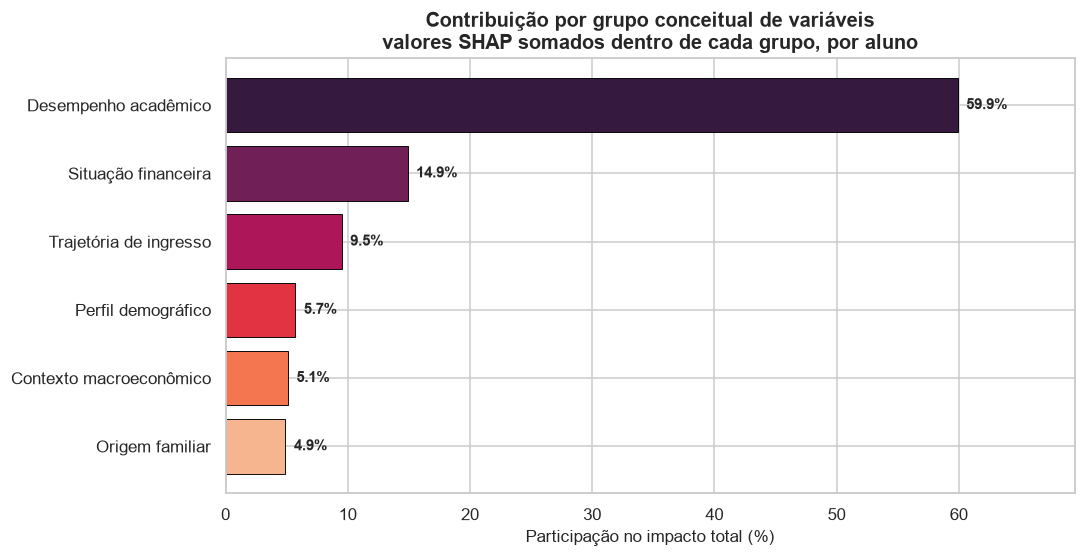

In [26]:
# --- Impacto agregado por grupo conceitual de variáveis --------------------
GRUPOS = {
    "Desempenho acadêmico": [c for c in X_teste.columns if c.startswith("curricular_units")],
    "Situação financeira": ["tuition_fees_up_to_date", "debtor", "scholarship_holder"],
    "Perfil demográfico": ["age_at_enrollment", "gender", "marital_status", "displaced",
                           "international", "educational_special_needs", "nacionality"],
    "Trajetória de ingresso": ["admission_grade", "previous_qualification_grade",
                               "previous_qualification", "application_order",
                               "application_mode", "course", "daytime_evening_attendance"],
    "Origem familiar": ["mothers_qualification", "fathers_qualification",
                        "mothers_occupation", "fathers_occupation"],
    "Contexto macroeconômico": ["unemployment_rate", "inflation_rate", "gdp"],
}

linhas, cobertas = [], set()
for grupo, prefixos in GRUPOS.items():
    idx = [i for i, col in enumerate(X_teste.columns)
           if any(col == p or col.startswith(p + "_") for p in prefixos)]
    if not idx:
        continue
    cobertas.update(idx)
    # soma por aluno (linearidade), depois média do módulo
    total = np.abs(shap_valores.values[:, idx].sum(axis=1)).mean()
    linhas.append({"grupo": grupo, "n_features": len(idx), "impacto_medio": total})

grupos_df = (pd.DataFrame(linhas)
               .sort_values("impacto_medio", ascending=False)
               .reset_index(drop=True))
grupos_df["% do total"] = (
    grupos_df["impacto_medio"] / grupos_df["impacto_medio"].sum() * 100).round(1)
grupos_df.index += 1

faltantes = [c for i, c in enumerate(X_teste.columns) if i not in cobertas]
print(f"Features cobertas pelos grupos: {len(cobertas)} de {X_teste.shape[1]}")
if faltantes:
    print(f"Não classificadas: {faltantes}")
display(grupos_df.round(4))

fig, ax = plt.subplots(figsize=(10, 5.2))
ordem = grupos_df.iloc[::-1]
barras = ax.barh(ordem["grupo"], ordem["% do total"],
                 color=sns.color_palette("rocket_r", len(ordem)),
                 edgecolor="black", linewidth=0.6)
for barra, valor in zip(barras, ordem["% do total"]):
    ax.text(barra.get_width() + 0.7, barra.get_y() + barra.get_height() / 2,
            f"{valor:.1f}%", va="center", fontweight="bold", fontsize=10)
ax.set_xlabel("Participação no impacto total (%)")
ax.set_xlim(0, ordem["% do total"].max() * 1.16)
ax.set_title("Contribuição por grupo conceitual de variáveis\n"
             "valores SHAP somados dentro de cada grupo, por aluno", fontweight="bold")
plt.tight_layout()
salvar("20_shap_grupos_conceituais.png")
plt.show()

## 12. Recomendações para a gestão acadêmica

As recomendações abaixo derivam dos achados, mas respeitam a advertência da seção 2: **SHAP identifica
associação preditiva, não efeito causal**. Cada item indica **onde intervir** e, quando aplicável, o
que seria necessário para verificar se a intervenção funciona.

### R-1 · Monitorar aprovações por semestre como indicador primário

O fator dominante em todos os métodos. A mediana de disciplinas aprovadas no 2º semestre é **zero**
entre os evadidos e **seis** entre os concluintes.

- **Ação:** relatório automático ao fim de cada semestre listando alunos com aprovações abaixo do
  limiar identificado na seção 9.
- **Custo:** baixo — o dado já existe no sistema acadêmico.
- **Ressalva:** este indicador é **tardio**. Quando dispara, o aluno já parou de estudar. Serve para
  priorizar, não para prevenir.

### R-2 · Tratar inadimplência como alerta acadêmico, não apenas financeiro

Entre alunos com mensalidades em atraso, a evasão é de **86,6%**, contra 24,7% dos que estão em dia —
diferença de 61,8 pontos percentuais em uma única variável binária.

- **Ação:** integrar o sistema financeiro ao acadêmico, de modo que o atraso gere contato da
  coordenação, e não apenas cobrança.
- **Custo:** baixo — integração de sistemas existentes.
- **Ressalva causal importante:** a inadimplência pode ser **sintoma** da decisão de sair, não sua
  causa. O aluno que já decidiu abandonar naturalmente para de pagar. Sem um experimento, não se sabe
  quanto da associação é causal — mas mesmo como sintoma precoce o indicador é útil.

### R-3 · Ampliar e priorizar a concessão de bolsas

Bolsistas evadem a **12,2%**, contra 38,7% dos não bolsistas — menos de um terço do risco. O SHAP
confirma efeito protetor consistente.

- **Ação:** priorizar a concessão para alunos que combinem os fatores de risco identificados.
- **Custo:** alto — envolve orçamento.
- **Ressalva:** há **viés de seleção** provável. Bolsas costumam exigir desempenho mínimo, de modo que
  bolsistas já são um grupo selecionado. Parte do efeito observado pode refletir a seleção, não a
  bolsa. **Este é o item que mais precisaria de um estudo experimental** antes de sustentar decisão
  orçamentária.

### R-4 · Acompanhamento diferenciado para ingressantes mais velhos

Idade maior no ingresso aumenta consistentemente o risco (mediana de 23 anos entre evadidos, 19 entre
concluintes).

- **Ação:** oferta de turmas noturnas, flexibilização de prazos, apoio a estudantes que trabalham.
- **Custo:** médio.
- **Ressalva:** a idade é um **marcador**, não uma causa. O que provavelmente opera são as
  responsabilidades concorrentes que a acompanham. A intervenção deve mirar essas responsabilidades.

### R-5 · Usar a explicação individual para encaminhar ao setor correto

Esta é a recomendação que só o SHAP viabiliza, e a mais diretamente ligada ao objetivo do TCC.

- **Ação:** o alerta entregue à coordenação deve incluir os **três principais fatores** do aluno, e o
  encaminhamento deve seguir o fator dominante:

| Fator dominante no SHAP | Encaminhamento |
|---|---|
| Inadimplência, ausência de bolsa | Assistência estudantil / setor financeiro |
| Reprovações, notas baixas | Apoio pedagógico / monitoria / tutoria |
| Poucas avaliações realizadas | Contato direto — possível abandono em curso |
| Idade, turno noturno | Orientação sobre flexibilização de carga |

- **Custo:** baixo — é o próprio produto do modelo.
- **Valor:** evita o desperdício de tratar todos os alunos sinalizados da mesma forma.

### R-6 · Comunicar o sistema como priorização, nunca como veredito

Os **29 falsos negativos** desta partição — 44 em uma partição típica, pela Verificação 2 — mostram
que há evasões cujas causas não estão nos dados (caso C da seção 10). Um aluno **não sinalizado não é
um aluno seguro**.

- **Ação:** treinar a coordenação para tratar a lista como priorização de atenção limitada, mantendo
  os canais tradicionais de acolhimento ativos para quem não aparece nela.
- **Custo:** nulo — é decisão de comunicação.
- **Por que importa:** se o sistema for apresentado como definitivo, a primeira evasão não prevista
  destruirá sua credibilidade interna. Declarar a limitação desde o início protege a ferramenta.

### R-7 · Calibrar o limiar conforme a capacidade de atendimento

A análise da seção 9 do Notebook 3 quantificou o trade-off. Baixar o limiar de 0,50 para **0,30**
reduz os evadidos não detectados de 29 para 12 — **17 alunos resgatados** ao custo de 34 conversas
adicionais.

- **Ação:** definir o limiar a partir da capacidade real da equipe de apoio, não do padrão de 0,50.
- **Custo:** nulo — é um parâmetro.
- **Observação:** esta é uma decisão de **política acadêmica**, não de modelagem. O trabalho entrega os
  números; a escolha é institucional.

## 13. Persistência dos resultados

In [27]:
# --- Artefatos para a monografia -------------------------------------------
saidas = {
    "shap_importancia_global.csv": importancia.reset_index(names="posicao"),
    "shap_direcao_efeito.csv": direcao.reset_index(names="posicao"),
    "shap_variaveis_recompostas.csv": agrupado.drop(columns="coluna").reset_index(names="posicao"),
    "shap_grupos_conceituais.csv": grupos_df.reset_index(names="posicao"),
    "shap_convergencia_metodos.csv": comparacao,
}
for nome, objeto in saidas.items():
    caminho = os.path.join(DIR_DADOS, nome)
    objeto.to_csv(caminho, index=False, encoding="utf-8")
    print(f"   [salvo] {caminho:<48} {objeto.shape}")

# Valores SHAP completos, para reanálise sem recalcular
caminho_npz = os.path.join(DIR_DADOS, "shap_valores_teste.npz")
np.savez_compressed(
    caminho_npz,
    valores=shap_valores.values,
    valor_base=shap_valores.base_values,
    dados=shap_valores.data,
    features=np.array(X_teste.columns, dtype=object),
    features_pt=np.array(NOMES_PT, dtype=object),
)
print(f"   [salvo] {caminho_npz}")

# Casos individuais documentados
casos_json = {
    etiqueta: {
        "indice_teste": int(idx),
        "situacao_real": CLASSES[int(diagnostico.loc[idx, "real"])],
        "predicao": CLASSES[int(diagnostico.loc[idx, "predito"])],
        "probabilidade_evasao": float(diagnostico.loc[idx, "prob_evasao"]),
        "principais_fatores": [
            {"variavel": r["variável"], "shap": float(r["SHAP"]), "direcao": r["direção"]}
            for _, r in fatores(idx, 5).iterrows()
        ],
    }
    for etiqueta, idx in CASOS.items()
}
caminho_casos = os.path.join(DIR_DADOS, "shap_casos_individuais.json")
with open(caminho_casos, "w", encoding="utf-8") as fh:
    json.dump(casos_json, fh, ensure_ascii=False, indent=2)
print(f"   [salvo] {caminho_casos}")

   [salvo] dados\shap_importancia_global.csv                (105, 5)
   [salvo] dados\shap_direcao_efeito.csv                    (15, 5)
   [salvo] dados\shap_variaveis_recompostas.csv             (35, 5)
   [salvo] dados\shap_grupos_conceituais.csv                (6, 5)
   [salvo] dados\shap_convergencia_metodos.csv              (27, 8)
   [salvo] dados\shap_valores_teste.npz
   [salvo] dados\shap_casos_individuais.json


In [28]:
# --- Conferência final ------------------------------------------------------
verificacoes = {
    "aditividade preservada": erro_max < 1e-4,
    "todas as 105 features explicadas": shap_valores.values.shape[1] == X_teste.shape[1],
    "todos os 726 alunos explicados": shap_valores.values.shape[0] == len(X_teste),
    "rótulos em português sem duplicatas": len(set(NOMES_PT)) == len(NOMES_PT),
    "recomposição preserva a soma": bool(np.allclose(
        shap_por_variavel.to_numpy().sum(axis=1),
        shap_valores.values.sum(axis=1), atol=1e-4)),
    "três casos individuais selecionados": len(CASOS) == 3,
}
for descricao, ok in verificacoes.items():
    print(f"   [{'OK' if ok else 'FALHA'}] {descricao}")

print()
print(f"erro máximo da aditividade  : {erro_max:.3e}")
print(f"tolerância adotada           : 1e-04   (float32: eps = {np.finfo(np.float32).eps:.2e})")

assert all(verificacoes.values()), "Verificação falhou — revisar antes de usar os resultados."
print("\nFase 5 concluída. Resultados consistentes.")

   [OK] aditividade preservada
   [OK] todas as 105 features explicadas
   [OK] todos os 726 alunos explicados
   [OK] rótulos em português sem duplicatas
   [OK] recomposição preserva a soma
   [OK] três casos individuais selecionados

erro máximo da aditividade  : 3.815e-06
tolerância adotada           : 1e-04   (float32: eps = 1.19e-07)

Fase 5 concluída. Resultados consistentes.


## 14. Síntese da Fase 5 do CRISP-DM

### O que foi feito

| Item | Detalhe |
|---|---|
| Explainer | `shap.TreeExplainer` (TreeSHAP) — valores de Shapley **exatos**, sem amostragem |
| Cobertura | 726 alunos × 105 features = 76.230 contribuições calculadas |
| Verificação | Aditividade conferida: a soma reconstrói a predição com erro na casa de 10⁻⁶ |
| Escala | Log-odds, com conversão para probabilidade nas análises individuais |
| Recomposição | *Dummies* somadas por variável original, usando a linearidade de Shapley |
| Artefatos | 5 CSVs, valores SHAP completos em `.npz`, casos individuais em JSON, 9 figuras |

### Os quatro achados desta fase

1. **A hierarquia dos fatores se confirma por um terceiro método independente.** Correlação linear
   (NB1), redução de impureza (NB2) e valores de Shapley (NB4) convergem: desempenho acadêmico inicial
   primeiro, situação financeira em seguida. Uma conclusão que sobrevive a três operacionalizações
   distintas é substancialmente mais robusta que uma obtida por um método só.

2. **A direção do efeito agora é explícita e quantificada.** O que antes era "idade importa" passa a
   ser "idade alta aumenta o risco, com magnitude X" — e essa é a informação que uma coordenação
   consegue usar. A tabela da seção 6 é o resultado central do trabalho.

3. **A recomposição das categóricas corrige a hierarquia.** Variáveis nominais apareciam
   artificialmente pequenas por estarem divididas em dezenas de *dummies*. Somadas, sobem — e é esse o
   ranking correto quando a pergunta é "quais fatores importam?" em vez de "quais features do modelo
   importam?".

4. **Três variáveis têm efeito condicional oposto ao marginal.** Este é o achado mais valioso da
   fase, e não estava previsto. *Deslocado da cidade de origem* e *disciplinas matriculadas no 1º
   semestre* **invertem de sinal** entre a análise descritiva e o SHAP; a *taxa de desemprego* tem
   correlação marginal nula (−0,004) e é a **9ª variável mais importante** do modelo. A análise
   descritiva do Notebook 1, isolada, levaria a conclusões erradas sobre as três — o que justifica por
   evidência a decisão de não fazer seleção de variáveis (D-17).

5. **O falso negativo revela um teto intrínseco.** O caso C mostra um aluno que evadiu tendo perfil
   protetor em todos os indicadores disponíveis. As causas de parte das evasões **não estão nos
   dados** — nenhum ajuste de modelagem recuperaria esses 29 alunos, que seriam 44 em uma partição
   típica (Verificação 2). É limite do conjunto de variáveis, não do algoritmo.

### O que a interpretabilidade acrescentou ao trabalho

O Notebook 3 mostrou que Random Forest e XGBoost têm métricas idênticas e ainda assim discordam sobre
24 alunos. Naquele momento, ficou o registro de que métricas agregadas são insuficientes quando o uso
é individual.

Esta fase entregou o que faltava: **cada aluno sinalizado vem acompanhado do motivo**, com contribuição
quantificada e auditável por variável. É isso que permite a recomendação R-5 — encaminhar ao setor
correto conforme o fator dominante — e é isso que separa uma lista de nomes de um instrumento de
gestão.

### Limitação central desta fase

> **SHAP explica o modelo, não o mundo.** Todos os valores medem como o XGBoost usa cada variável, e
> não o efeito causal da variável sobre a evasão. As recomendações da seção 12 identificam **onde
> intervir**; verificar **se a intervenção funciona** exigiria delineamento experimental — em especial
> no caso das bolsas (R-3), onde há viés de seleção provável.
>
> Essa distinção precisa ser mantida na redação da monografia. Confundir associação preditiva com
> efeito causal é o erro mais comum na aplicação de interpretabilidade a políticas públicas, e o mais
> fácil de a banca identificar.

### Próximo passo

**Notebook 5 — Relatório final:** consolidação dos resultados, tabela final de métricas, top 10 dos
fatores de risco, limitações e trabalhos futuros.